# Práctica 6 · Detección de rostros con ventana deslizante e image pyramid

**Objetivo.** Detectar rostros en escenas con fondos complejos y rostros de distinto tamaño, resolviendo los dos desafíos clásicos de la detección de objetos:

| Desafío | Problema | Solución |
|---|---|---|
| **1 · Ubicación** | El rostro puede estar en cualquier región | **Ventana deslizante** (`sliding_window`) |
| **2a · Tamaño** | Rostro **mayor** que la ventana | **Pirámide que reduce** (`s > 1`) |
| **2b · Tamaño** | Rostro **menor** que la ventana | **Pirámide que amplía** (`s < 1`, `upsample_levels`) |

**Pipeline.** pirámide → ventana deslizante → clasificación por lotes con una CNN preentrenada (ResNet-10 SSD, pesos oficiales de OpenCV) → mapeo inverso a la imagen original → NMS → recuadro verde con su probabilidad.

**Pirámide y mapeo inverso.** El nivel $l$ usa el factor $s=\text{escala}^{\,l}$ (mismo factor en ancho y alto ⇒ se conserva el *aspect ratio*): $l>0$ reduce, $l=0$ es el original y $l<0$ amplía. Una ventana en $(x,y)$ de ese nivel corresponde en la imagen original a
$x_1=\mathrm{round}(x\,s),\; y_1=\mathrm{round}(y\,s),\; x_2=\mathrm{round}((x+w)\,s),\; y_2=\mathrm{round}((y+h)\,s)$ (válido para $s>1$ y $s<1$).

### Parámetros por defecto (módulo y notebook)
| Parámetro | Valor | Función |
|---|---|---|
| Ventana | 96×96 px | tamaño fijo del escaneo |
| Confianza mínima | 0.90 | umbral para aceptar una ventana |
| NMS (IoU) | 0.30 | solape máximo entre recuadros finales |
| Alineación mínima | 0.60 | IoU entre la caja del SSD (cuadrada) y la ventana |
| Contexto | 0.50 × lado | margen neutro alrededor de cada ventana |
| Contención (NMS) | 0.40 | suprime cajas con > 40 % de su área dentro de otra mejor |
| Lote | 32 | ventanas por `net.forward()` |
| `upsample_levels` | 0 | niveles de ampliación (0 = comportamiento clásico) |

### Decisiones de diseño
1. **Modelo.** `cv2.dnn.readNetFromCaffe` con `deploy.prototxt` + `res10_300x300_ssd_iter_140000.caffemodel`: pesos reales, todas las probabilidades salen de la inferencia.
2. **Alineación.** El SSD es un *detector* (devuelve cajas), no un clasificador de parches. Cada caja se vuelve cuadrada (lado $\sqrt{w\,h}$) y se mide su IoU con la ventana; solo cuentan las cajas con alineación $\ge 0.60$. Con alineación $\ge 0.60$ un rostro cuadrado contenido en la ventana debe medir al menos $\sqrt{0.60}\approx 0.775$ de su lado (≈ 74 px en una ventana de 96).
3. **Prioridad en NMS = confianza × alineación.** Muchas ventanas tienen confianza ≈ 1.0 (empates): se conserva la mejor centrada y se reporta la confianza real de la red.
4. **NMS + contención.** Una ventana de 96 px *dentro* de un rostro de 190 px tiene IoU ≈ 0.26 (96²/190²), que el NMS clásico (0.30) no suprime; la regla de contención sí.
5. **Contexto.** Un parche de 96 px ampliado a 300×300 queda fuera de la distribución del SSD y produce falsos positivos; el margen neutro lo evita. Su efecto y el de la alineación se miden en la sección 7.
6. **Umbral 0.90** (la guía pide ≥ 0.80), elegido mirando estas imágenes: no hay conjunto de validación. En el desarrollo, con 0.80 el *Paso Fino* aceptó una ventana sobre el transbordador del fondo (82.7 %); es una observación previa que este notebook no reproduce.
7. **Límites de la pirámide.** La reducción se detiene cuando un nivel es menor que la ventana; una ampliación se omite si su lado mayor supera 1600 px.

> **Tiempo de ejecución.** La red solo admite entrada 300×300 y corre en CPU (`cv2.dnn`, sin aceleración por GPU), a ≈ 35 ventanas/s. Las corridas idénticas se reutilizan (caché de `detectar`), por lo que la ejecución completa debería rondar los 11–12 min.

## 1 · Entorno y dependencias

In [1]:
import os, sys, json, subprocess
import cv2

# La serie 5.x de OpenCV eliminó el importador de Caffe: se necesita la 4.x
if not hasattr(cv2.dnn, "readNetFromCaffe"):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "opencv-python-headless<5"], check=True)
    raise RuntimeError("Se instaló OpenCV 4.x. Reinicia el kernel (Run > Restart) y ejecuta de nuevo.")

print("OpenCV", cv2.__version__)
OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.path.abspath(".")
os.chdir(OUT_DIR)
print("Directorio de salida:", OUT_DIR)

OpenCV 4.14.0
Directorio de salida: /kaggle/working


## 2 · Módulo de la práctica (`practica_6_deteccion_rostros.py`)
La celda siguiente escribe el **módulo autocontenido** que usa la app (`smile_core.py`): `image_pyramid`, `sliding_window`, `puntuar_lote`, `non_max_suppression`, `detect_faces`, `draw_detections` y una línea de comandos (`--step`, `--scale`, `--upsample`, …). **Este notebook es la fuente de verdad**: el resto de las celdas lo importan, de modo que notebook y app ejecutan exactamente el mismo código.

In [2]:
%%writefile practica_6_deteccion_rostros.py
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
Práctica 6: Detección de Rostros con Ventana Deslizante + Pirámide de Imágenes
==============================================================================

Propósito del módulo
--------------------
Pipeline clásico-convolucional de detección de rostros:
  1. Pirámide de imágenes (multiescala, conserva la relación de aspecto). Reduce
     la imagen para rostros MAYORES que la ventana (desafío 2a) y, opcionalmente,
     la amplía para rostros MENORES que la ventana (desafío 2b, ``--upsample``).
  2. Ventana deslizante de tamaño fijo (96×96 px por defecto) sobre cada nivel.
  3. Cada ventana se clasifica en lotes con la red ResNet-10 SSD de Caffe,
     cargada con cv2.dnn.readNetFromCaffe.
  4. Mapeo inverso de las ventanas aceptadas a coordenadas de la imagen original.
  5. Supresión de No Máximos (NMS) para dejar un único recuadro por rostro.

Cómo ejecutarlo
---------------
    python practica_6_deteccion_rostros.py ruta/imagen.jpg --step 16 --scale 1.25
    python practica_6_deteccion_rostros.py ruta/imagen.jpg --step 24 --scale 1.4 --upsample 1

Dependencias
------------
    numpy, opencv-python (serie 4.x; la serie 5.x eliminó el importador Caffe).

Archivos que necesita
---------------------
    models/deploy.prototxt                        – arquitectura de la red (se descarga si falta)
    models/res10_300x300_ssd_iter_140000.caffemodel – pesos de la red (se descarga si falta)
"""
import argparse
import json
import os
import sys
import time
import urllib.request

import cv2
import numpy as np

# --------------------------------------------------------------------------
# Modelo preentrenado (pesos oficiales de OpenCV)
# --------------------------------------------------------------------------
PROTO_NAME = "deploy.prototxt"
MODEL_NAME = "res10_300x300_ssd_iter_140000.caffemodel"
PROTO_URL = ("https://raw.githubusercontent.com/opencv/opencv/4.x/"
             "samples/dnn/face_detector/deploy.prototxt")
MODEL_URL = ("https://raw.githubusercontent.com/opencv/opencv_3rdparty/"
             "dnn_samples_face_detector_20170830/" + MODEL_NAME)
MEAN_BGR = (104.0, 177.0, 123.0)   # media de los canales BGR con la que fue entrenada la red
NET_INPUT = (300, 300)             # tamaño de entrada fijo requerido por el SSD
MAX_LADO_AMPLIADO = 1600           # una ampliación de la pirámide se omite si su lado mayor lo supera
FACTOR_ROSTRO_MIN = 0.775          # ≈ sqrt(0.60): lado mínimo del rostro / lado de la ventana con min_cover=0.60


def resolver_directorio_modelo(directorio="models"):
    """Localiza la carpeta que contiene el archivo deploy.prototxt.

    Busca primero en el directorio indicado y luego en las rutas habituales
    ('models', 'modelo', '.').  Si no encuentra nada, devuelve el directorio
    indicado por defecto para que la descarga lo cree.

    Args:
        directorio (str): Carpeta preferida donde buscar el modelo.

    Returns:
        str: Ruta al directorio donde existe (o se creará) el modelo.
    """
    if directorio and os.path.exists(os.path.join(directorio, PROTO_NAME)):
        return directorio
    for d in ("models", "modelo", "."):
        if os.path.exists(os.path.join(d, PROTO_NAME)):
            return d
    return directorio or "models"


def descargar_modelo(directorio="models"):
    """Descarga deploy.prototxt y los pesos .caffemodel si no existen o están incompletos.

    Args:
        directorio (str): Carpeta donde guardar los archivos descargados.

    Returns:
        tuple[str, str]: Rutas (proto, pesos) de los archivos descargados/existentes.
    """
    directorio = resolver_directorio_modelo(directorio)
    os.makedirs(directorio, exist_ok=True)
    rutas = []
    for nombre, url in ((PROTO_NAME, PROTO_URL), (MODEL_NAME, MODEL_URL)):
        ruta = os.path.join(directorio, nombre)
        if not os.path.exists(ruta) or os.path.getsize(ruta) < 1000:
            print(f"[modelo] descargando {nombre} ...")
            urllib.request.urlretrieve(url, ruta)
        rutas.append(ruta)
    return rutas[0], rutas[1]


def cargar_red(directorio="models"):
    """Carga la red ResNet-10 SSD con pesos oficiales (sin inicialización aleatoria).

    Verifica que la versión de OpenCV soporte el importador Caffe (serie 4.x).

    Args:
        directorio (str): Carpeta donde están (o se descargarán) los archivos del modelo.

    Returns:
        cv2.dnn_Net: Red neuronal lista para inferencia.

    Raises:
        RuntimeError: Si OpenCV no incluye el importador Caffe (p.ej. serie 5.x).
    """
    directorio = resolver_directorio_modelo(directorio)
    if not hasattr(cv2.dnn, "readNetFromCaffe"):
        raise RuntimeError(
            f"OpenCV {cv2.__version__} no incluye el importador Caffe. "
            "Instala la serie 4.x: pip install 'opencv-python-headless<5'")
    proto, pesos = descargar_modelo(directorio)
    return cv2.dnn.readNetFromCaffe(proto, pesos)


# --------------------------------------------------------------------------
# Desafío 2: variabilidad de tamaño -> Pirámide de imágenes
# --------------------------------------------------------------------------
def image_pyramid(image, scale=1.25, min_size=(96, 96), upsample_levels=0):
    """Generador de pirámide de imágenes multiescala.

    El nivel ``l`` se obtiene dividiendo la imagen por ``s = scale**l`` (mismo
    factor en ancho y alto => se preserva el aspect ratio):

    * ``l > 0``: REDUCCIÓN (``s > 1``, ``cv2.INTER_AREA``).  Permite que un rostro
      mayor que la ventana quepa en ella (desafío 2a).  Se detiene cuando algún
      lado de la imagen reducida es menor que ``min_size``.
    * ``l = 0``: imagen original (``s = 1``).
    * ``l < 0``: AMPLIACIÓN (``s < 1``, ``cv2.INTER_CUBIC``), solo si
      ``upsample_levels > 0``.  Permite que un rostro menor que la ventana la
      llene (desafío 2b).  El nivel ``-k`` usa ``s = scale**(-k)``, ``k = 1..n``.

    Orden de salida: de mayor ampliación a mayor reducción (``-n, ..., -1, 0, 1, ...``).
    Un nivel ampliado se omite si su lado mayor supera ``MAX_LADO_AMPLIADO`` (1600 px).

    El factor ``s`` permite mapear las coordenadas de cualquier nivel a la imagen
    original multiplicando por ``s`` (ver ``detect_faces``); funciona con ``s < 1``.

    Args:
        image (np.ndarray): Imagen BGR original.
        scale (float): Factor entre niveles consecutivos (p.ej. 1.25 → cada
            nivel es 1/1.25 del anterior en cada dimensión).
        min_size (tuple[int, int]): Tamaño mínimo (ancho, alto) para seguir
            generando niveles de reducción.
        upsample_levels (int): Número de niveles de ampliación (0 = solo reducción,
            comportamiento clásico).

    Yields:
        tuple[int, float, np.ndarray]: (nivel, factor_escala, imagen_del_nivel).
            ``factor_escala`` es ``scale**nivel`` respecto a la imagen original.
    """
    h0, w0 = image.shape[:2]
    # Niveles de ampliación: de la mayor ampliación a la menor (s = scale**-k, k = n..1)
    for k in range(upsample_levels, 0, -1):
        s = scale ** (-k)
        w, h = int(round(w0 / s)), int(round(h0 / s))
        if max(w, h) > MAX_LADO_AMPLIADO:
            continue
        yield -k, s, cv2.resize(image, (w, h), interpolation=cv2.INTER_CUBIC)
    # Nivel 0: imagen original sin modificar; factor = 1.0
    yield 0, 1.0, image
    level = 0
    while True:
        level += 1
        s = scale ** level                      # factor acumulado desde el original
        w, h = int(round(w0 / s)), int(round(h0 / s))
        # Condición de parada: si algún lado cae bajo el mínimo, se termina la pirámide
        if w < min_size[0] or h < min_size[1]:
            break
        yield level, s, cv2.resize(image, (w, h), interpolation=cv2.INTER_AREA)


# --------------------------------------------------------------------------
# Desafío 1: variabilidad de ubicación -> Ventana deslizante
# --------------------------------------------------------------------------
def sliding_window(image, step_size, window_size):
    """Recorre la imagen con una ventana de tamaño fijo, generando parches.

    El tamaño de la ventana lo fija ``window_size`` (96×96 px por defecto en el
    resto del módulo).  El paso ``step_size`` controla cuántos píxeles avanza en cada iteración:
    un paso pequeño (p.ej. 8-16) da más cobertura a costa de más ventanas.

    Args:
        image (np.ndarray): Imagen (nivel de la pirámide) a recorrer.
        step_size (int): Desplazamiento en píxeles entre ventanas consecutivas
            (tanto en X como en Y). Configurable vía --step en la CLI.
        window_size (tuple[int, int]): (ancho, alto) de la ventana en píxeles.
            Por defecto el módulo usa (96, 96).

    Yields:
        tuple[int, int, np.ndarray]: (x, y, parche) donde (x, y) es la esquina
            superior-izquierda de la ventana dentro de ``image``.
    """
    win_w, win_h = window_size
    H, W = image.shape[:2]
    for y in range(0, H - win_h + 1, step_size):
        for x in range(0, W - win_w + 1, step_size):
            yield x, y, image[y:y + win_h, x:x + win_w]


# --------------------------------------------------------------------------
# Clasificación por lotes con la red convolucional
# --------------------------------------------------------------------------
def puntuar_lote(net, patches, min_cover=0.60, context=0.50):
    """Evalúa un lote de parches (ventanas cuadradas) con UN solo net.forward().

    Estrategia de contexto
    ~~~~~~~~~~~~~~~~~~~~~~
    Cada parche se rodea con un margen neutro (píxeles iguales a la media del
    entrenamiento, que equivale a 0 tras restar ``MEAN_BGR``) de ``context`` x
    lado de la ventana por cada lado.  Sin él, un parche de 96 px ampliado a
    300x300 queda "fuera de distribución" y el SSD produce falsos positivos
    (p.ej. una cuchara de la imagen del café se acepta con > 0.9 de confianza; ver ablación 2×2 del notebook).  El contexto
    rodea el parche de colores neutros para que la red "vea" el parche como si
    estuviera en el centro de una imagen más grande.

    Cálculo del puntaje de cada ventana y alineación IoU
    ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
    1. El SSD devuelve cajas de rostro [x1, y1, x2, y2] con su probabilidad.
    2. Cada caja se convierte a cuadrada (lado = sqrt(ancho x alto), mismo centro).
    3. Se mide la ALINEACIÓN = IoU(caja cuadrada, ventana completa [0,1]x[0,1]).
    4. Solo cuentan las cajas con alineación >= ``min_cover``; el puntaje de la
       ventana es la máxima confianza entre ellas.  Así, una ventana desplazada
       o cuyo tamaño no coincide con el del rostro no hereda su confianza y el
       recuadro final se ajusta al verdadero tamaño del rostro.

    Args:
        net (cv2.dnn_Net): Red SSD ya cargada (misma instancia para todos los lotes).
        patches (list[np.ndarray]): Lista de parches BGR de tamaño ``window_size``.
        min_cover (float): Alineación mínima (IoU entre la caja del SSD y la
            ventana) para aceptar una detección.
        context (float): Fracción del lado de la ventana que se añade como
            margen neutro alrededor del parche antes de pasarlo a la red.

    Returns:
        tuple[np.ndarray, np.ndarray]:
            - confianzas (float32, len=len(patches)): probabilidad de rostro
              de la red, continua en [0, 1].
            - alineaciones (float32, len=len(patches)): IoU de la mejor caja
              aceptada con la ventana completa (0 si ninguna cumple min_cover).
    """
    win = patches[0].shape[0]
    pad = int(round(context * win))
    canvas = win + 2 * pad
    if pad > 0:
        # Añadir margen neutro (color medio del entrenamiento) para contextualizar cada parche
        patches = [cv2.copyMakeBorder(p, pad, pad, pad, pad, cv2.BORDER_CONSTANT,
                                      value=MEAN_BGR) for p in patches]
    blob = cv2.dnn.blobFromImages(patches, 1.0, NET_INPUT, MEAN_BGR,
                                  swapRB=False, crop=False)
    net.setInput(blob)
    dets = net.forward()[0, 0]                  # (N_det, 7): id, clase, conf, x1, y1, x2, y2
    scores = np.zeros(len(patches), dtype=np.float32)
    aligns = np.zeros(len(patches), dtype=np.float32)
    if dets.shape[0] == 0:
        return scores, aligns
    ids = dets[:, 0].astype(int)
    conf = dets[:, 2]
    # Convertir cajas normalizadas del lienzo a coordenadas relativas a la ventana [0, 1]
    b = (dets[:, 3:7] * canvas - pad) / float(win)
    w = np.clip(b[:, 2] - b[:, 0], 0, None)
    h = np.clip(b[:, 3] - b[:, 1], 0, None)
    # Convertir a caja cuadrada: mismo centro, lado = sqrt(ancho * alto)
    side = np.sqrt(w * h)
    cx, cy = (b[:, 0] + b[:, 2]) / 2, (b[:, 1] + b[:, 3]) / 2
    # Calcular IoU entre la caja cuadrada y la ventana completa [0,1]x[0,1]
    iw = np.clip(np.minimum(cx + side / 2, 1) - np.maximum(cx - side / 2, 0), 0, None)
    ih = np.clip(np.minimum(cy + side / 2, 1) - np.maximum(cy - side / 2, 0), 0, None)
    inter = iw * ih
    # IoU = intersección / (1 + área_caja_cuadrada - intersección); el +1 es el área de la ventana
    align = inter / (1.0 + side * side - inter + 1e-9)
    ok = (ids >= 0) & (ids < len(patches)) & (conf > 0) & (align >= min_cover)
    np.maximum.at(scores, ids[ok], conf[ok])
    mejor = ok & (conf >= scores[np.clip(ids, 0, len(patches) - 1)])
    aligns[ids[mejor]] = align[mejor]
    return scores, aligns


# --------------------------------------------------------------------------
# Supresión de No Máximos (vectorizada)
# --------------------------------------------------------------------------
def non_max_suppression(boxes, scores, overlap_thresh=0.3, contain_thresh=None):
    """Supresión de No Máximos (NMS) sobre cajas [x1, y1, x2, y2].

    Ordena las cajas por puntuación descendente.  Para cada caja de máxima
    puntuación calcula el IoU (Intersection over Union) con las restantes
    de forma vectorizada y elimina las que se solapan más de ``overlap_thresh``.

    Extensión opcional (``contain_thresh``): también elimina las cajas cuya
    intersección con la mejor caja supera esa fracción de SU PROPIA área.
    Esto elimina cajas pequeñas contenidas dentro de otra mayor (p.ej. una
    caja de 96 px dentro de otra de 190 px tendría IoU ≈ 0.26, que el NMS
    clásico no quitaría).

    Args:
        boxes (array-like): Cajas de forma (N, 4) con columnas [x1, y1, x2, y2].
        scores (array-like): Puntuaciones de cada caja (mayor = mejor).
        overlap_thresh (float): Umbral de IoU por encima del cual se suprime
            una caja solapada.
        contain_thresh (float | None): Fracción de la propia área de la caja
            más pequeña que, si se supera por intersección con la mayor, la
            elimina.  None desactiva esta extensión.

    Returns:
        np.ndarray: Índices (int) de las cajas conservadas, ordenados por puntuación.
    """
    boxes = np.asarray(boxes, dtype=np.float64).reshape(-1, 4)
    scores = np.asarray(scores, dtype=np.float64)
    if boxes.shape[0] == 0:
        return np.array([], dtype=int)
    x1, y1, x2, y2 = boxes.T
    areas = (x2 - x1) * (y2 - y1)
    orden = np.argsort(-scores)
    keep = []
    while orden.size > 0:
        i = orden[0]
        keep.append(i)
        resto = orden[1:]
        # Intersección vectorizada: la mejor caja contra todas las restantes
        xx1 = np.maximum(x1[i], x1[resto])
        yy1 = np.maximum(y1[i], y1[resto])
        xx2 = np.minimum(x2[i], x2[resto])
        yy2 = np.minimum(y2[i], y2[resto])
        inter = np.clip(xx2 - xx1, 0, None) * np.clip(yy2 - yy1, 0, None)
        # IoU = intersección / unión
        iou = inter / (areas[i] + areas[resto] - inter + 1e-9)
        suprimir = iou > overlap_thresh
        # Extensión: suprimir cajas pequeñas contenidas en la mejor
        if contain_thresh is not None:
            suprimir |= inter / (np.minimum(areas[i], areas[resto]) + 1e-9) > contain_thresh
        orden = resto[~suprimir]
    return np.array(keep, dtype=int)


# --------------------------------------------------------------------------
# Detector completo
# --------------------------------------------------------------------------
def detect_faces(image_bgr, net, window_size=(96, 96), step_size=16, scale=1.25,
                 conf_threshold=0.90, overlap_thresh=0.3, batch_size=32,
                 min_cover=0.60, context=0.50, contain_thresh=0.40, min_size=None,
                 upsample_levels=0):
    """Ejecuta el pipeline completo: pirámide + ventana deslizante + red + NMS.

    Los parches de TODOS los niveles de la pirámide se acumulan en lotes de
    ``batch_size`` antes de llamar a la red, minimizando el número de llamadas
    a ``net.forward()``.

    Mapeo inverso a la imagen original
    ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
    Cuando una ventana de coordenadas ``(x, y)`` en el nivel ``l`` (escala ``s``)
    se acepta, sus coordenadas reales en la imagen original son:
        x_orig = x * s,  y_orig = y * s.
    Esto se debe a que el nivel ``l`` fue creado dividiendo la imagen original
    por ``s``, por lo que multiplicar por ``s`` deshace esa reducción (``s > 1``)
    o esa ampliación (``s < 1``, niveles de ``upsample_levels``).

    Args:
        image_bgr (np.ndarray): Imagen BGR de entrada.
        net (cv2.dnn_Net): Red SSD ya cargada.
        window_size (tuple[int, int]): Tamaño de la ventana deslizante en px.
            Por defecto (96, 96).
        step_size (int): Paso de la ventana deslizante en px.
        scale (float): Factor de reducción entre niveles de la pirámide.
        conf_threshold (float): Umbral de confianza mínimo para aceptar una ventana.
        overlap_thresh (float): Umbral de IoU del NMS.
        batch_size (int): Número de ventanas enviadas a la red de una sola vez.
        min_cover (float): Alineación mínima caja-ventana requerida en ``puntuar_lote``.
        context (float): Margen de contexto alrededor de cada ventana (ver ``puntuar_lote``).
        contain_thresh (float): Umbral de contención del NMS (ver ``non_max_suppression``).
        min_size (tuple[int, int] | None): Tamaño mínimo de imagen en la pirámide;
            si None se usa ``window_size``.
        upsample_levels (int): Niveles de ampliación de la pirámide (0 = solo
            reducción, comportamiento clásico). Ver ``image_pyramid``.

    Returns:
        dict: Diccionario con las siguientes claves:
            - ``boxes`` (np.ndarray int (K,4)): Cajas finales [x1,y1,x2,y2] en coords. orig.
            - ``scores`` (np.ndarray float (K,)): Confianzas finales.
            - ``raw_boxes``, ``raw_scores``: Cajas y confianzas antes del NMS.
            - ``niveles`` (int): Número de niveles de la pirámide usados.
            - ``ventanas_por_nivel`` (list[int]): Ventanas por nivel.
            - ``total_ventanas`` (int): Total de ventanas evaluadas.
            - ``detecciones_brutas`` (int): Número de ventanas aceptadas antes del NMS.
            - ``detecciones_finales`` (int): Número de rostros tras el NMS.
            - ``tiempo_s`` (float): Tiempo total en segundos.
            - ``upsample_levels`` (int): Niveles de ampliación solicitados.
            - ``tam_min_rostro_px`` (float): Lado mínimo de rostro (en px de la imagen
              original) que una ventana puede alinear con ``min_cover=0.60``:
              ``0.775 * ancho_ventana * s_min``, con ``s_min = scale**(-upsample_levels)``
              (o la mayor ampliación realmente usada si el tope de 1600 px omitió niveles).
    """
    win_w, win_h = window_size
    # Un nivel cuyo lado sea menor que la ventana no puede contener ni una ventana completa
    min_size = (max(win_w, (min_size or (0, 0))[0]), max(win_h, (min_size or (0, 0))[1]))
    H0, W0 = image_bgr.shape[:2]

    t0 = time.perf_counter()
    raw_boxes, raw_scores, raw_rank = [], [], []
    niveles, ventanas_por_nivel = 0, []
    total = 0
    s_min = 1.0                                 # menor factor s realmente usado (mayor ampliación)
    buf_patches, buf_meta = [], []

    def vaciar_lote():
        """Envía el buffer actual a la red y acumula las detecciones aceptadas."""
        if not buf_patches:
            return
        sc, al = puntuar_lote(net, buf_patches, min_cover, context)
        for (x, y, s), p, a in zip(buf_meta, sc, al):
            if p >= conf_threshold:
                # Mapeo inverso a la imagen original: coordenadas del nivel × factor s
                x1o, y1o = int(round(x * s)), int(round(y * s))
                x2o, y2o = int(round((x + win_w) * s)), int(round((y + win_h) * s))
                raw_boxes.append([max(0, x1o), max(0, y1o), min(W0, x2o), min(H0, y2o)])
                raw_scores.append(float(p))
                raw_rank.append(float(p * a))   # prioridad en NMS: confianza x alineación
        buf_patches.clear()
        buf_meta.clear()

    for level, s, resized in image_pyramid(image_bgr, scale, min_size, upsample_levels):
        niveles += 1
        s_min = min(s_min, s)
        n_nivel = 0
        for x, y, patch in sliding_window(resized, step_size, window_size):
            buf_patches.append(patch)
            buf_meta.append((x, y, s))
            n_nivel += 1
            if len(buf_patches) >= batch_size:
                vaciar_lote()
        ventanas_por_nivel.append(n_nivel)
        total += n_nivel
    vaciar_lote()

    raw_boxes = np.array(raw_boxes, dtype=int).reshape(-1, 4)
    raw_scores = np.array(raw_scores, dtype=float)
    raw_rank = np.array(raw_rank, dtype=float)
    # NMS ordena por confianza x alineación (desempata a favor de la ventana mejor centrada
    # cuando varias tienen confianza ~1.0); se reporta la confianza real al exterior.
    keep = non_max_suppression(raw_boxes, raw_rank, overlap_thresh, contain_thresh)
    elapsed = time.perf_counter() - t0
    return {
        "boxes": raw_boxes[keep], "scores": raw_scores[keep],
        "raw_boxes": raw_boxes, "raw_scores": raw_scores,
        "niveles": niveles, "ventanas_por_nivel": ventanas_por_nivel,
        "total_ventanas": total, "detecciones_brutas": int(len(raw_boxes)),
        "detecciones_finales": int(len(keep)), "tiempo_s": elapsed,
        "upsample_levels": int(upsample_levels),
        "tam_min_rostro_px": FACTOR_ROSTRO_MIN * win_w * s_min,
    }


# --------------------------------------------------------------------------
# Visualización
# --------------------------------------------------------------------------
def draw_detections(image_bgr, boxes, scores, color=(0, 255, 0), thickness=3):
    """Dibuja recuadros verdes (3 px) con el texto 'Rostro: XX.X%'.

    Args:
        image_bgr (np.ndarray): Imagen BGR sobre la que dibujar.
        boxes (array-like): Cajas [x1, y1, x2, y2] de las detecciones.
        scores (array-like): Confianzas correspondientes a cada caja.
        color (tuple[int,int,int]): Color BGR de los recuadros.
        thickness (int): Grosor de los recuadros en píxeles.

    Returns:
        np.ndarray: Copia de la imagen con las anotaciones dibujadas.
    """
    out = image_bgr.copy()
    fs = max(0.5, min(out.shape[:2]) / 600.0)
    for (x1, y1, x2, y2), sc in zip(boxes, scores):
        cv2.rectangle(out, (int(x1), int(y1)), (int(x2), int(y2)), color, thickness)
        txt = f"Rostro: {sc * 100:.1f}%"
        (tw, th), base = cv2.getTextSize(txt, cv2.FONT_HERSHEY_SIMPLEX, fs, 2)
        # etiqueta justo encima del borde (sin tapar el trazo); si no cabe, debajo
        ty = int(y1) - thickness - base - 2 if y1 - th - base - thickness - 8 > 0 else int(y2) + th + thickness + 4
        tx = int(min(max(x1, 0), max(out.shape[1] - tw - 2, 0)))
        cv2.rectangle(out, (tx, ty - th - 4), (tx + tw, ty + base), (0, 0, 0), -1)
        cv2.putText(out, txt, (tx, ty), cv2.FONT_HERSHEY_SIMPLEX, fs, color, 2, cv2.LINE_AA)
    return out


# --------------------------------------------------------------------------
# Línea de comandos
# --------------------------------------------------------------------------
def main(argv=None):
    """Punto de entrada para uso por consola.

    Args:
        argv (list[str] | None): Argumentos de la línea de comandos.
            None → usa sys.argv.
    """
    ap = argparse.ArgumentParser(description="Detección de rostros: ventana deslizante + pirámide")
    ap.add_argument("imagen", help="ruta de la imagen a procesar")
    ap.add_argument("--step", type=int, default=16, help="paso de la ventana (8, 16, 24)")
    ap.add_argument("--scale", type=float, default=1.25, help="factor de la pirámide (1.15-1.40)")
    ap.add_argument("--ventana", type=int, default=96, help="lado de la ventana en px")
    ap.add_argument("--conf", type=float, default=0.90, help="umbral de confianza (>= 0.80)")
    ap.add_argument("--nms", type=float, default=0.30, help="umbral de solape del NMS")
    ap.add_argument("--alineacion", type=float, default=0.60,
                    help="alineación mínima caja-ventana (IoU) para aceptar una ventana")
    ap.add_argument("--contencion", type=float, default=0.40,
                    help="suprime cajas contenidas en otra mejor (fracción de su área)")
    ap.add_argument("--batch", type=int, default=32, help="tamaño de lote")
    ap.add_argument("--contexto", type=float, default=0.50,
                    help="margen de contexto alrededor de cada ventana (fracción del lado)")
    ap.add_argument("--upsample", type=int, default=0,
                    help="niveles de AMPLIACIÓN de la pirámide para rostros menores que la ventana")
    ap.add_argument("--max-lado", type=int, default=800,
                    help="reduce imágenes más grandes (ahorra tiempo); 0 = no reducir")
    default_dir = "models" if os.path.isdir("models") else "modelo"
    ap.add_argument("--modelo-dir", default=default_dir, help="carpeta del modelo Caffe")
    ap.add_argument("--salida", default="resultado_deteccion.png", help="imagen de salida")
    ap.add_argument("--json", default=None, help="guardar detecciones en JSON (opcional)")
    a = ap.parse_args(argv)

    img = cv2.imread(a.imagen)
    if img is None:
        sys.exit(f"No se pudo leer la imagen: {a.imagen}")
    factor = 1.0
    if a.max_lado and max(img.shape[:2]) > a.max_lado:
        factor = a.max_lado / max(img.shape[:2])
        img = cv2.resize(img, None, fx=factor, fy=factor, interpolation=cv2.INTER_AREA)
        print(f"[info] imagen reducida x{factor:.3f} para acelerar el escaneo")

    net = cargar_red(a.modelo_dir)
    r = detect_faces(img, net, (a.ventana, a.ventana), a.step, a.scale, a.conf,
                     a.nms, a.batch, min_cover=a.alineacion, context=a.contexto,
                     contain_thresh=a.contencion, upsample_levels=a.upsample)
    print(f"Niveles: {r['niveles']} | Ventanas: {r['total_ventanas']} | "
          f"Brutas: {r['detecciones_brutas']} | Finales: {r['detecciones_finales']} | "
          f"Tiempo: {r['tiempo_s']:.1f} s")
    if a.upsample > 0:
        print(f"Rostro mínimo detectable ≈ {r['tam_min_rostro_px']:.0f} px (con {a.upsample} nivel(es) de ampliación)")
    for b, s in zip(r["boxes"], r["scores"]):
        print(f"  Rostro {s * 100:.1f}%  caja={b.tolist()}")
    cv2.imwrite(a.salida, draw_detections(img, r["boxes"], r["scores"]))
    print(f"Resultado guardado en {a.salida}")
    if a.json:
        with open(a.json, "w", encoding="utf-8") as f:
            json.dump({"boxes": r["boxes"].tolist(), "scores": r["scores"].tolist(),
                       "factor_reduccion": factor}, f, indent=2)


if __name__ == "__main__":
    main()

Writing practica_6_deteccion_rostros.py


In [3]:
import hashlib, inspect
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from skimage import data
from IPython.display import display, Markdown

import practica_6_deteccion_rostros as p6
from practica_6_deteccion_rostros import (cargar_red, image_pyramid, sliding_window,
                                          detect_faces, draw_detections)

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

# ---- Hiperparámetros globales (iguales a los valores por defecto del módulo) ----
WINDOW    = (96, 96)   # ventana deslizante
CONF_THR  = 0.90       # umbral de confianza (la guía pide >= 0.80)
NMS_THR   = 0.30       # solape máximo permitido en NMS
BATCH     = 32         # tamaño de lote para net.forward()
MIN_COVER = 0.60       # alineación mínima (IoU caja cuadrada-ventana)
CONTAIN   = 0.40       # NMS por contención
CONTEXT   = 0.50       # margen de contexto (fracción del lado de la ventana)

_d = {k: v.default for k, v in inspect.signature(detect_faces).parameters.items()}
assert (_d["window_size"], _d["conf_threshold"], _d["overlap_thresh"], _d["batch_size"], _d["min_cover"],
        _d["context"], _d["contain_thresh"], _d["upsample_levels"]) == (WINDOW, CONF_THR, NMS_THR, BATCH,
                                                                         MIN_COVER, CONTEXT, CONTAIN, 0), \
    "Los hiperparámetros del notebook no coinciden con los valores por defecto del módulo"

rgb2bgr = lambda im: cv2.cvtColor(im, cv2.COLOR_RGB2BGR)
bgr2rgb = lambda im: cv2.cvtColor(im, cv2.COLOR_BGR2RGB)

FIGURAS, TABLAS = [], {}            # figuras PNG y tablas (DataFrame) que exporta la sección 11
def guardar_fig(nombre):
    plt.savefig(nombre, bbox_inches="tight"); FIGURAS.append(nombre)

net = cargar_red(os.path.join(OUT_DIR, "models"))   # descarga los pesos oficiales si faltan (Internet: On)
print("Red cargada · capas:", len(net.getLayerNames()))

_CACHE = {}
def detectar(img_bgr, step, scale, *, ventana=WINDOW[0], context=CONTEXT, min_cover=MIN_COVER, upsample=0):
    """detect_faces con los hiperparámetros globales. Una corrida idéntica (misma imagen y mismos
    parámetros) no se repite: se devuelve el resultado ya calculado."""
    clave = (hashlib.md5(img_bgr.tobytes()).hexdigest(), img_bgr.shape, ventana, step, scale,
             context, min_cover, upsample)
    if clave in _CACHE:
        print("   (corrida idéntica ya ejecutada: se reutiliza el resultado)")
        return _CACHE[clave]
    r = detect_faces(img_bgr, net, (ventana, ventana), step, scale, CONF_THR, NMS_THR, BATCH,
                     min_cover, context, CONTAIN, upsample_levels=upsample)
    _CACHE[clave] = r
    return r

[modelo] descargando deploy.prototxt ...
[modelo] descargando res10_300x300_ssd_iter_140000.caffemodel ...
Red cargada · capas: 112


## 3 · Dataset de evaluación (3 casos)
| Caso | Descripción | Qué valida |
|---|---|---|
| 1 | `data.astronaut()` (512×512): rostro mediano (≈ 100 px) sobre fondo estructurado | Ubicación + escala ≈ ventana |
| 2 | Retrato con rostro dominante (≈ 190 px) | Niveles que reducen (Desafío 2a) |
| 3 | `data.coffee()`: sin personas | Especificidad: **0 detecciones** |

El Desafío 2b (rostro menor que la ventana) usa una imagen propia, la sección 9.

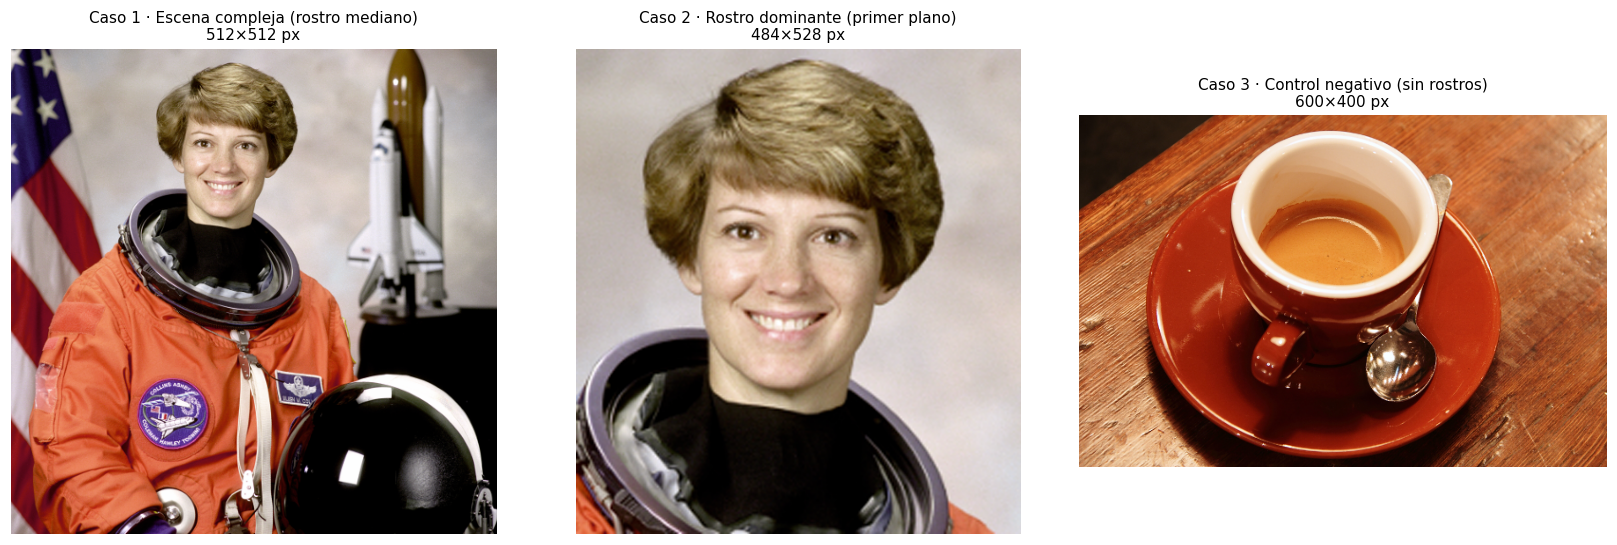

In [4]:
def preparar_casos():
    astro = data.astronaut()                                   # Caso 1
    recorte = astro[10:250, 120:340]                           # cabeza y hombros
    retrato = cv2.resize(recorte, None, fx=2.2, fy=2.2, interpolation=cv2.INTER_CUBIC)  # Caso 2
    cafe = data.coffee()                                       # Caso 3
    return {
        1: ("Caso 1 · Escena compleja (rostro mediano)", astro),
        2: ("Caso 2 · Rostro dominante (primer plano)", retrato),
        3: ("Caso 3 · Control negativo (sin rostros)", cafe),
    }

casos = preparar_casos()
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, k in zip(axs, (1, 2, 3)):
    t, im = casos[k]
    ax.imshow(im); ax.set_title(f"{t}\n{im.shape[1]}×{im.shape[0]} px", fontsize=10); ax.axis("off")
plt.tight_layout(); guardar_fig("dataset_evaluacion_deteccion.png"); plt.show()

## 4 · Pirámide de imágenes y ventana deslizante
En el nivel $l$ la imagen mide $W/s \times H/s$ y la ventana fija de 96×96 equivale a **96·s px** de la imagen original. Cada nivel aporta $\big(\lfloor (W_l-96)/\text{paso}\rfloor+1\big)\big(\lfloor (H_l-96)/\text{paso}\rfloor+1\big)$ ventanas. Las tablas muestran la pirámide del Caso 1 para la configuración **estándar** (paso 16, escala 1.25) y la **rápida** (paso 24, escala 1.40), y la figura, la ventana fija sobre el rostro en cada nivel (Desafío 2a).

In [5]:
def tabla_piramide(img, step, scale, upsample=0):
    """Una fila por nivel: factor s, tamaño del nivel, tamaño efectivo de la ventana y ventanas."""
    filas = []
    for l, s, im in image_pyramid(img, scale, WINDOW, upsample):
        filas.append({"Nivel": l, "Factor s": round(s, 3), "Imagen (px)": f"{im.shape[1]}×{im.shape[0]}",
                      "Ventana efectiva en el original (px)": round(WINDOW[0] * s, 1),
                      "Ventanas": sum(1 for _ in sliding_window(im, step, WINDOW))})
    return pd.DataFrame(filas)

img1_rgb = casos[1][1]
for clave, titulo, step, scale in (("piramide_estandar", "Configuración estándar (paso 16, escala 1.25)", 16, 1.25),
                                   ("piramide_rapida", "Configuración rápida (paso 24, escala 1.40)", 24, 1.40)):
    TABLAS[clave] = tabla_piramide(img1_rgb, step, scale)
    display(Markdown(f"**{titulo}** · {len(TABLAS[clave])} niveles · {TABLAS[clave]['Ventanas'].sum()} ventanas"))
    display(TABLAS[clave])

**Configuración estándar (paso 16, escala 1.25)** · 8 niveles · 1574 ventanas

,Nivel,Factor s,Imagen (px),Ventana efectiva en el original (px),Ventanas
0,0,1.000,512×512,96.0,729
1,1,1.250,410×410,120.0,400
2,2,1.562,328×328,150.0,225
3,3,1.953,262×262,187.5,121
4,4,2.441,210×210,234.4,64
5,5,3.052,168×168,293.0,25
6,6,3.815,134×134,366.2,9
7,7,4.768,107×107,457.8,1


**Configuración rápida (paso 24, escala 1.40)** · 5 niveles · 537 ventanas

,Nivel,Factor s,Imagen (px),Ventana efectiva en el original (px),Ventanas
0,0,1.000,512×512,96.0,324
1,1,1.400,366×366,134.4,144
2,2,1.960,261×261,188.2,49
3,3,2.744,187×187,263.4,16
4,4,3.842,133×133,368.8,4


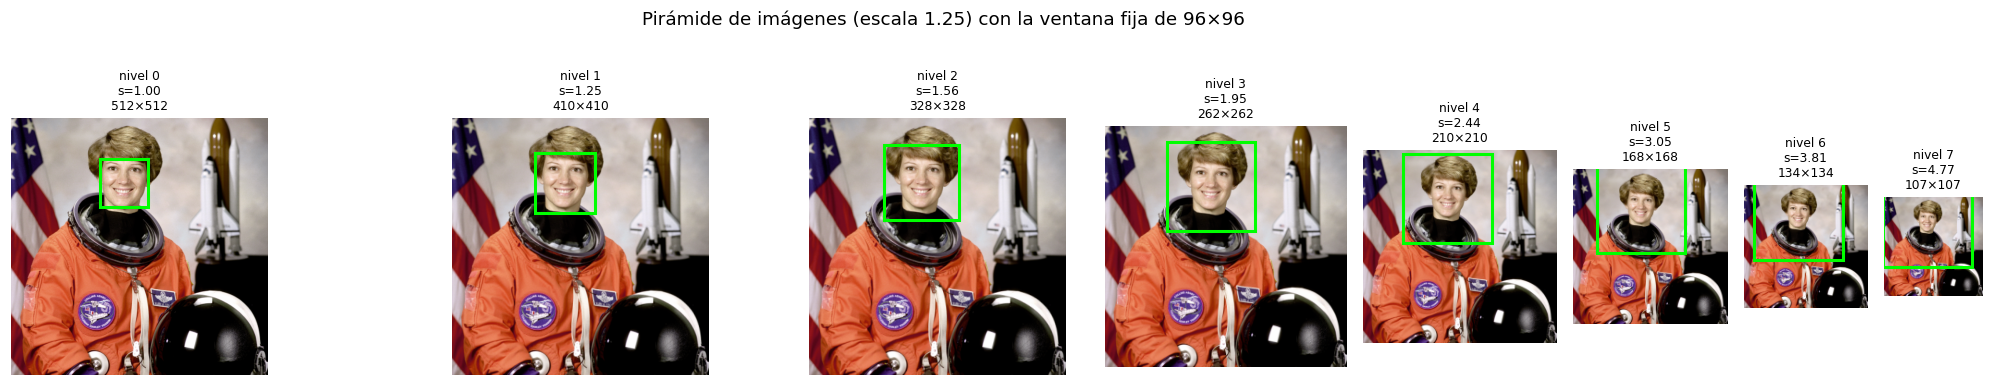

In [6]:
niveles = list(image_pyramid(img1_rgb, 1.25, WINDOW))
fig, axs = plt.subplots(1, len(niveles), figsize=(2.4 * len(niveles), 3.4),
                        gridspec_kw={"width_ratios": [im.shape[1] for _, _, im in niveles]})
cx, cy = 224, 128   # centro del rostro en la imagen original (centro de la caja final del Caso 1)
for ax, (l, s, im) in zip(axs, niveles):
    ax.imshow(im)
    ax.add_patch(Rectangle((cx / s - 48, cy / s - 48), 96, 96, fill=False, ec="lime", lw=2))
    ax.set_title(f"nivel {l}\ns={s:.2f}\n{im.shape[1]}×{im.shape[0]}", fontsize=8)
    ax.axis("off")
plt.suptitle("Pirámide de imágenes (escala 1.25) con la ventana fija de 96×96", y=1.02)
plt.tight_layout(); guardar_fig("piramide_imagenes.png"); plt.show()

## 5 · Benchmark paramétrico (Caso 1)
Tres configuraciones de escaneo sobre la imagen principal. Los parches de **todos los niveles** se acumulan en lotes de 32 y se procesan con un único `net.forward()` por lote.

In [7]:
CONFIGS = [("Paso Fino", 8, 1.15), ("Paso Estándar", 16, 1.25), ("Paso Rápido", 24, 1.40)]
img1_bgr = rgb2bgr(casos[1][1])

res_bench, filas = {}, []
for nombre, step, scale in CONFIGS:
    print(f"▶ {nombre} (paso={step}, escala={scale}) ...", flush=True)
    r = detectar(img1_bgr, step, scale)
    res_bench[nombre] = r
    filas.append({
        "Configuración": nombre, "Paso (px)": step, "Factor de escala": scale,
        "Niveles de pirámide": r["niveles"], "Ventanas evaluadas": r["total_ventanas"],
        "Detecciones brutas": r["detecciones_brutas"], "Detecciones finales (NMS)": r["detecciones_finales"],
        "Tiempo (s)": round(r["tiempo_s"], 2),
        "Confianza máx.": round(float(r["scores"].max()), 4) if len(r["scores"]) else None,
    })
    print(f"   {r['total_ventanas']} ventanas · {r['detecciones_brutas']} brutas → {r['detecciones_finales']} finales · {r['tiempo_s']:.1f} s")

df_bench = pd.DataFrame(filas)
df_bench["Ventanas/s"] = (df_bench["Ventanas evaluadas"] / df_bench["Tiempo (s)"]).round(1)
TABLAS["benchmark_caso1"] = df_bench
display(df_bench)

▶ Paso Fino (paso=8, escala=1.15) ...
   8676 ventanas · 78 brutas → 1 finales · 258.1 s
▶ Paso Estándar (paso=16, escala=1.25) ...
   1574 ventanas · 15 brutas → 1 finales · 46.5 s
▶ Paso Rápido (paso=24, escala=1.4) ...
   537 ventanas · 4 brutas → 1 finales · 16.2 s


,Configuración,Paso (px),Factor de escala,Niveles de pirámide,Ventanas evaluadas,Detecciones brutas,Detecciones finales (NMS),Tiempo (s),Confianza máx.,Ventanas/s
0,Paso Fino,8,1.15,13,8676,78,1,258.15,1.0000,33.6
1,Paso Estándar,16,1.25,8,1574,15,1,46.54,1.0000,33.8
2,Paso Rápido,24,1.40,5,537,4,1,16.20,0.9993,33.1


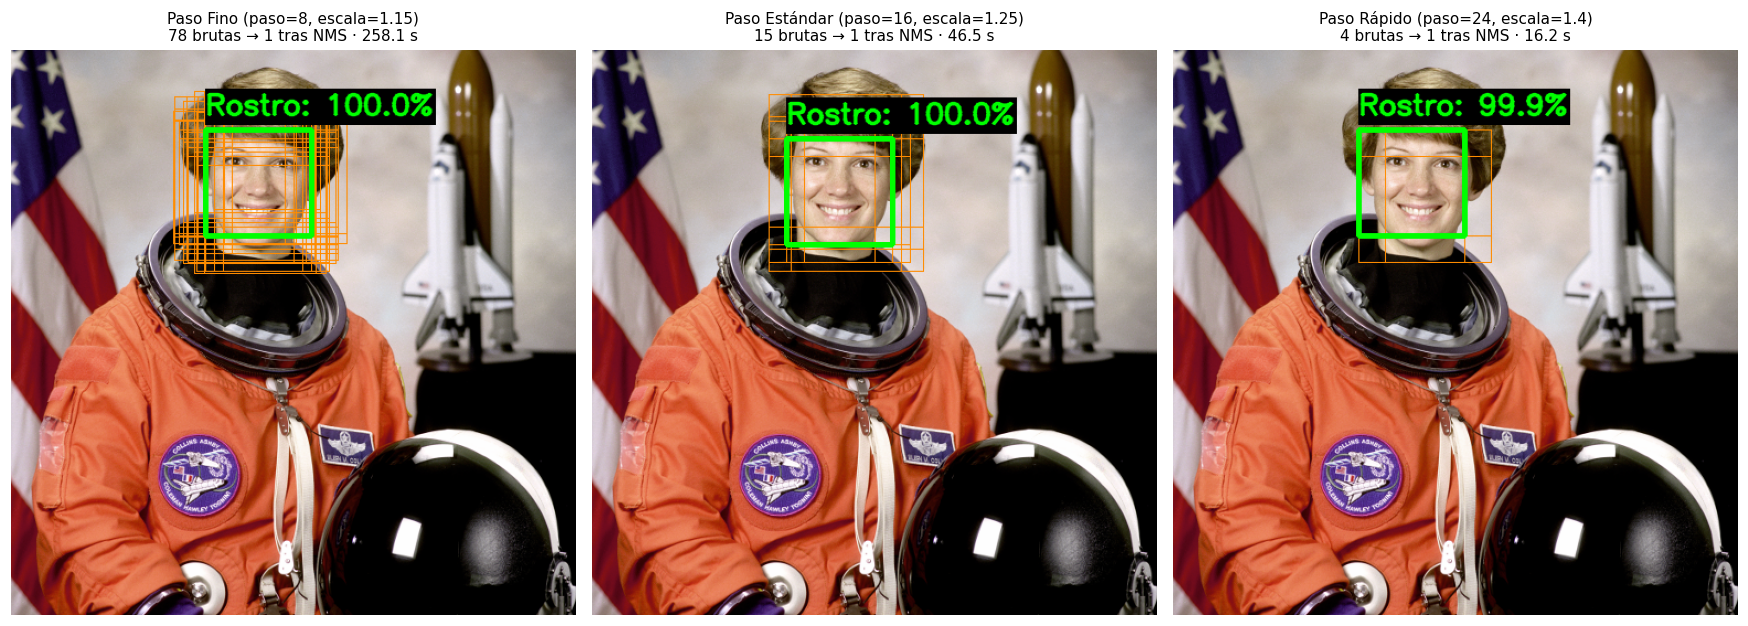

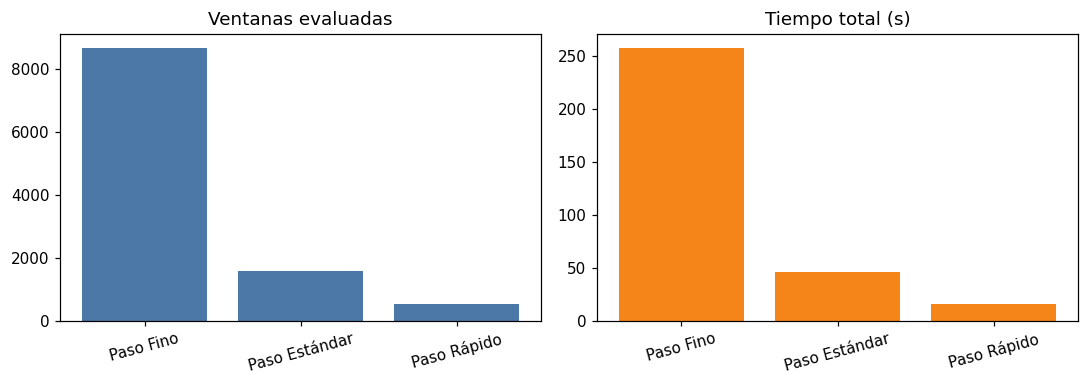

In [8]:
# --- Comparativa visual: detecciones brutas (naranja, 1 px) vs finales tras NMS (verde, 3 px)
fig, axs = plt.subplots(1, 3, figsize=(16, 5.6))
for ax, (nombre, step, scale) in zip(axs, CONFIGS):
    r = res_bench[nombre]
    vis = img1_bgr.copy()
    for (x1, y1, x2, y2) in r["raw_boxes"]:
        cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 140, 255), 1)
    vis = draw_detections(vis, r["boxes"], r["scores"])
    ax.imshow(bgr2rgb(vis)); ax.axis("off")
    ax.set_title(f"{nombre} (paso={step}, escala={scale})\n{r['detecciones_brutas']} brutas → {r['detecciones_finales']} tras NMS · {r['tiempo_s']:.1f} s", fontsize=10)
plt.tight_layout(); guardar_fig("comparativa_configuraciones.png"); plt.show()

# --- Costo vs configuración
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
axs[0].bar(df_bench["Configuración"], df_bench["Ventanas evaluadas"], color="#4c78a8"); axs[0].set_title("Ventanas evaluadas")
axs[1].bar(df_bench["Configuración"], df_bench["Tiempo (s)"], color="#f58518"); axs[1].set_title("Tiempo total (s)")
for a in axs: a.tick_params(axis="x", rotation=15)
plt.tight_layout(); guardar_fig("benchmark_rendimiento.png"); plt.show()

## 6 · Galería de detección (configuración estándar: paso 16, escala 1.25)
### 6.1 · Los tres casos
El Caso 1 reutiliza la ejecución *Paso Estándar* del benchmark; los casos 2 y 3 se evalúan con la misma configuración.

▶ Caso 1 ...
   (corrida idéntica ya ejecutada: se reutiliza el resultado)
   1574 ventanas · 15 brutas → 1 finales · 46.5 s
▶ Caso 2 ...
   1516 ventanas · 38 brutas → 1 finales · 45.4 s
▶ Caso 3 ...
   1397 ventanas · 0 brutas → 0 finales · 41.8 s


,Caso,Imagen (px),Niveles de pirámide,Ventanas evaluadas,Detecciones brutas,Detecciones finales,Caja final (px),Confianza,Tiempo (s)
0,1,512×512,8,1574,15,1,96×96,1.0000,46.54
1,2,484×528,8,1516,38,1,188×188,0.9999,45.37
2,3,600×400,7,1397,0,0,—,—,41.82


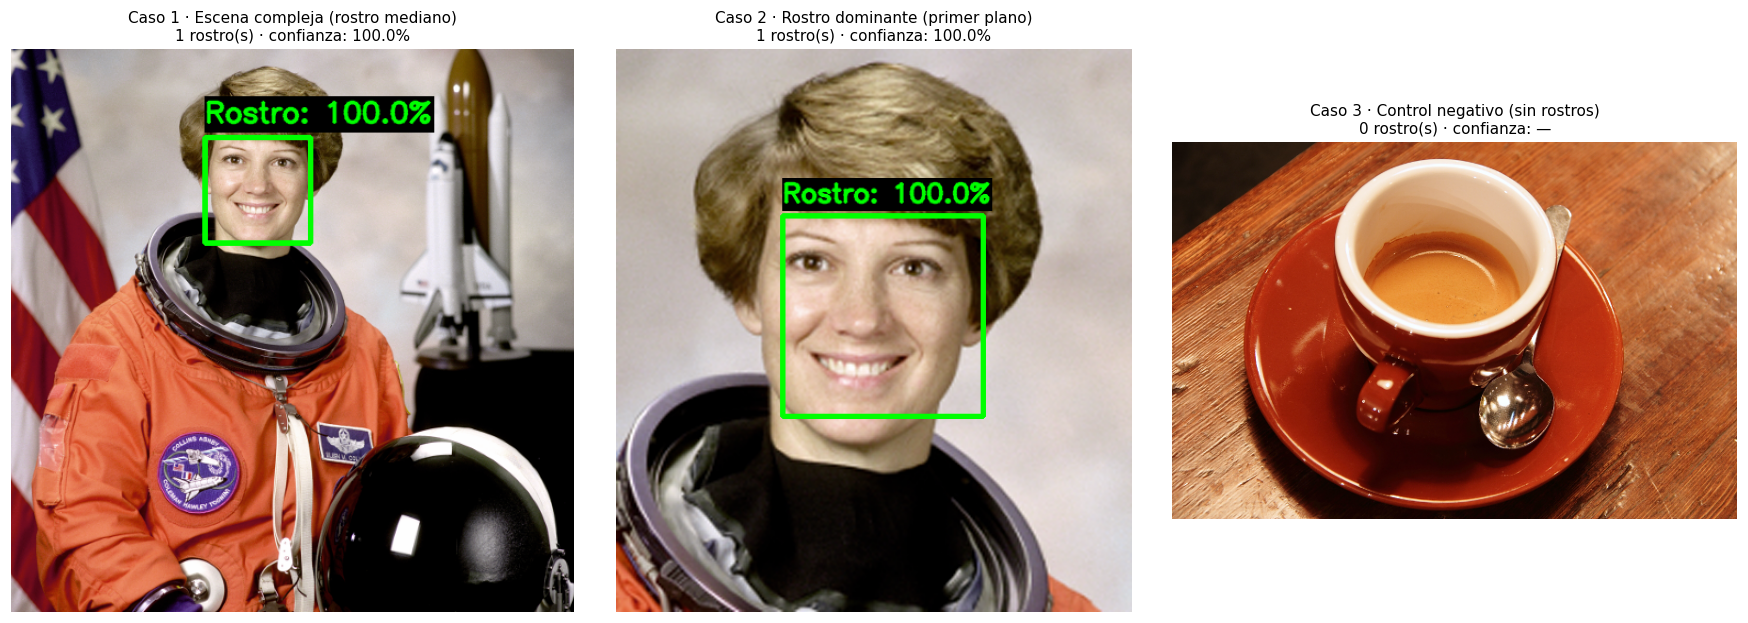

In [9]:
res_casos, filas_c = {}, []
for k in (1, 2, 3):
    print(f"▶ Caso {k} ...", flush=True)
    res_casos[k] = detectar(rgb2bgr(casos[k][1]), 16, 1.25)
    r = res_casos[k]
    print(f"   {r['total_ventanas']} ventanas · {r['detecciones_brutas']} brutas → {r['detecciones_finales']} finales · {r['tiempo_s']:.1f} s")
    filas_c.append({"Caso": k, "Imagen (px)": f"{casos[k][1].shape[1]}×{casos[k][1].shape[0]}",
                    "Niveles de pirámide": r["niveles"], "Ventanas evaluadas": r["total_ventanas"],
                    "Detecciones brutas": r["detecciones_brutas"], "Detecciones finales": r["detecciones_finales"],
                    "Caja final (px)": "; ".join(f"{int(b[2]-b[0])}×{int(b[3]-b[1])}" for b in r["boxes"]) or "—",
                    "Confianza": ", ".join(f"{s:.4f}" for s in r["scores"]) or "—",
                    "Tiempo (s)": round(r["tiempo_s"], 2)})
df_casos = pd.DataFrame(filas_c); TABLAS["casos_configuracion_estandar"] = df_casos
display(df_casos)

fig, axs = plt.subplots(1, 3, figsize=(16, 5.6))
for ax, k in zip(axs, (1, 2, 3)):
    t, im = casos[k]; r = res_casos[k]
    ax.imshow(bgr2rgb(draw_detections(rgb2bgr(im), r["boxes"], r["scores"])))
    conf = ", ".join(f"{s*100:.1f}%" for s in r["scores"]) or "—"
    ax.set_title(f"{t}\n{r['detecciones_finales']} rostro(s) · confianza: {conf}", fontsize=10); ax.axis("off")
plt.tight_layout(); guardar_fig("galeria_deteccion_rostros.png"); plt.show()

### 6.2 · Regresión (sin ampliación)
Con `upsample_levels=0` el módulo debe reproducir la corrida de referencia (`resultados_practica6.json`): mismas ventanas por nivel y mismas cajas finales. Los valores de referencia se copian aquí para que la celda funcione sin ese archivo. La celda falla (`assert`) si algo cambia.

In [10]:
# Valores de resultados_practica6.json (corrida de referencia, sin niveles de ampliación)
REF = {
    "Caso 1 · estándar (paso 16, escala 1.25)": dict(ventanas=1574, por_nivel=[729, 400, 225, 121, 64, 25, 9, 1],
                                                    caja=[176, 80, 272, 176], r=res_casos[1]),
    "Caso 2 · estándar (paso 16, escala 1.25)": dict(ventanas=1516, por_nivel=[700, 399, 224, 110, 56, 20, 6, 1],
                                                    caja=[156, 156, 344, 344], r=res_casos[2]),
    "Caso 3 · estándar (paso 16, escala 1.25)": dict(ventanas=1397, por_nivel=[640, 375, 209, 98, 50, 21, 4],
                                                    caja=None, r=res_casos[3]),
    # la caja del Paso Rápido figura en la ablación de ventana de 96 px del mismo JSON (misma configuración)
    "Caso 1 · Paso Rápido (paso 24, escala 1.40)": dict(ventanas=537, por_nivel=[324, 144, 49, 16, 4],
                                                       caja=[168, 72, 264, 168], r=res_bench["Paso Rápido"]),
}
filas_reg = []
for nombre, ref in REF.items():
    r = ref["r"]
    cajas = np.asarray(r["boxes"]).astype(int).tolist()
    ok_v = r["total_ventanas"] == ref["ventanas"]
    ok_n = list(r["ventanas_por_nivel"]) == ref["por_nivel"]
    ok_c = cajas == ([ref["caja"]] if ref["caja"] else [])
    filas_reg.append({"Prueba": nombre, "upsample_levels": r["upsample_levels"],
                      "Ventanas (obtenido / referencia)": f"{r['total_ventanas']} / {ref['ventanas']}",
                      "Caja final obtenida": cajas[0] if cajas else "—", "Caja referencia": ref["caja"] or "—",
                      "Ventanas": "✔" if ok_v else "✘", "Por nivel": "✔" if ok_n else "✘", "Caja": "✔" if ok_c else "✘"})
df_reg = pd.DataFrame(filas_reg); TABLAS["regresion_sin_ampliacion"] = df_reg
display(df_reg)

# La pirámide con upsample_levels=0 es idéntica a la clásica (mismos niveles, factores y píxeles)
for k in (1, 2, 3):
    A = list(image_pyramid(casos[k][1], 1.25, WINDOW)); B = list(image_pyramid(casos[k][1], 1.25, WINDOW, 0))
    assert len(A) == len(B) and all(a[0] == b[0] and a[1] == b[1] and np.array_equal(a[2], b[2]) for a, b in zip(A, B)), \
        f"Regresión: la pirámide del Caso {k} cambió con upsample_levels=0"
assert all(f["upsample_levels"] == 0 for f in filas_reg), "Regresión: se esperaba upsample_levels=0"
assert (df_reg[["Ventanas", "Por nivel", "Caja"]] == "✔").all().all(), "Regresión: difiere de resultados_practica6.json"
print("✔ Regresión superada: con upsample_levels=0 el resultado es idéntico a la corrida de referencia")

,Prueba,upsample_levels,Ventanas (obtenido / referencia),Caja final obtenida,Caja referencia,Ventanas,Por nivel,Caja
0,"Caso 1 · estándar (paso 16, escala 1.25)",0,1574 / 1574,"[176, 80, 272, 176]","[176, 80, 272, 176]",✔,✔,✔
1,"Caso 2 · estándar (paso 16, escala 1.25)",0,1516 / 1516,"[156, 156, 344, 344]","[156, 156, 344, 344]",✔,✔,✔
2,"Caso 3 · estándar (paso 16, escala 1.25)",0,1397 / 1397,—,—,✔,✔,✔
3,"Caso 1 · Paso Rápido (paso 24, escala 1.40)",0,537 / 537,"[168, 72, 264, 168]","[168, 72, 264, 168]",✔,✔,✔


✔ Regresión superada: con upsample_levels=0 el resultado es idéntico a la corrida de referencia


### 6.3 · Mapeo inverso con un ejemplo real
Se busca, en los resultados del Caso 2, el nivel y la posición de la ventana cuyo mapeo $x\cdot s,\;y\cdot s$ reproduce exactamente la caja final.

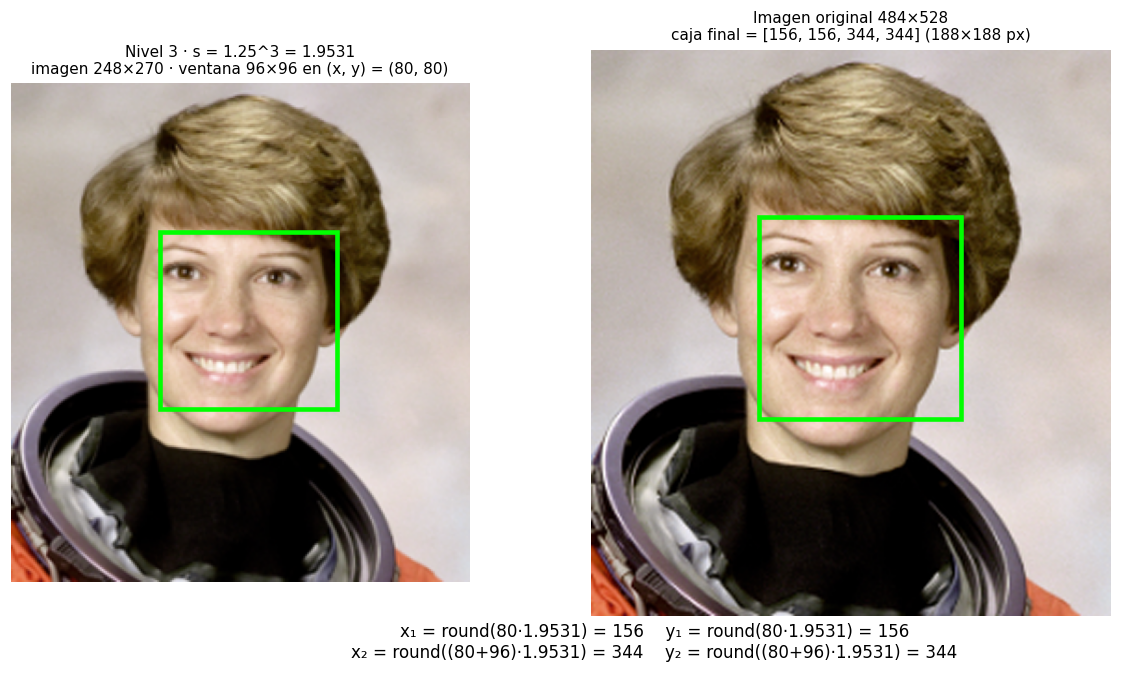

In [11]:
def ventana_de_origen(caja, scale, step, win, n_niveles):
    """(nivel, s, x, y) de la ventana del nivel cuyo mapeo inverso reproduce la caja final."""
    x1, y1, x2, y2 = [int(v) for v in caja]
    for l in range(n_niveles):
        s = scale ** l
        x, y = round(x1 / s / step) * step, round(y1 / s / step) * step
        if [round(x * s), round(y * s), round((x + win) * s), round((y + win) * s)] == [x1, y1, x2, y2]:
            return l, s, x, y
    return None

img2_rgb = casos[2][1]; r2 = res_casos[2]
origen = ventana_de_origen(r2["boxes"][0], 1.25, 16, WINDOW[0], r2["niveles"])
assert origen is not None, "No se encontró un nivel cuyo mapeo reproduzca la caja final del Caso 2"
nivel, s, x, y = origen
im_nivel = next(im for lv, _, im in image_pyramid(img2_rgb, 1.25, WINDOW) if lv == nivel)
X1, Y1, X2, Y2 = [int(v) for v in r2["boxes"][0]]

fig, axs = plt.subplots(1, 2, figsize=(12, 5.8), gridspec_kw={"width_ratios": [im_nivel.shape[1], img2_rgb.shape[1]]})
axs[0].imshow(im_nivel); axs[0].add_patch(Rectangle((x, y), 96, 96, fill=False, ec="lime", lw=3)); axs[0].axis("off")
axs[0].set_title(f"Nivel {nivel} · s = 1.25^{nivel} = {s:.4f}\nimagen {im_nivel.shape[1]}×{im_nivel.shape[0]} · ventana 96×96 en (x, y) = ({x}, {y})", fontsize=10)
axs[1].imshow(img2_rgb); axs[1].add_patch(Rectangle((X1, Y1), X2 - X1, Y2 - Y1, fill=False, ec="lime", lw=3)); axs[1].axis("off")
axs[1].set_title(f"Imagen original {img2_rgb.shape[1]}×{img2_rgb.shape[0]}\ncaja final = [{X1}, {Y1}, {X2}, {Y2}] ({X2-X1}×{Y2-Y1} px)", fontsize=10)
fig.text(0.5, -0.04, f"x₁ = round({x}·{s:.4f}) = {X1}    y₁ = round({y}·{s:.4f}) = {Y1}\n"
                     f"x₂ = round(({x}+96)·{s:.4f}) = {X2}    y₂ = round(({y}+96)·{s:.4f}) = {Y2}",
         ha="center", fontsize=11)
plt.tight_layout(); guardar_fig("mapeo_inverso.png"); plt.show()
MAPEO_EJEMPLO = {"caso": casos[2][0], "nivel": int(nivel), "s": round(float(s), 6), "ventana_en_el_nivel_xy": [int(x), int(y)],
                 "ventana_px": WINDOW[0], "caja_original_xyxy": [X1, Y1, X2, Y2]}

## 7 · Ablación 2×2 en el Caso 3 (control negativo)
Se combinan el **margen de contexto** (0 / 0.5) y el **filtro de alineación** (apagado, `min_cover=0` / 0.60). Cualquier detección es un falso positivo. Es una sola imagen: indica el efecto de cada mecanismo, no su importancia general. La combinación (0.5, 0.60) es la configuración estándar del Caso 3 y se reutiliza.

▶ contexto=0.0 · alineación mínima=0.0 ...
▶ contexto=0.0 · alineación mínima=0.6 ...
▶ contexto=0.5 · alineación mínima=0.0 ...
▶ contexto=0.5 · alineación mínima=0.6 ...
   (corrida idéntica ya ejecutada: se reutiliza el resultado)


,Contexto (× lado),Alineación mín.,Ventanas aceptadas,Detecciones finales,Confianza máx. FP,Tiempo (s)
0,0.0,0.0,3,1,0.924,41.8
1,0.0,0.6,0,0,0.000,36.3
2,0.5,0.0,0,0,0.000,42.1
3,0.5,0.6,0,0,0.000,41.8


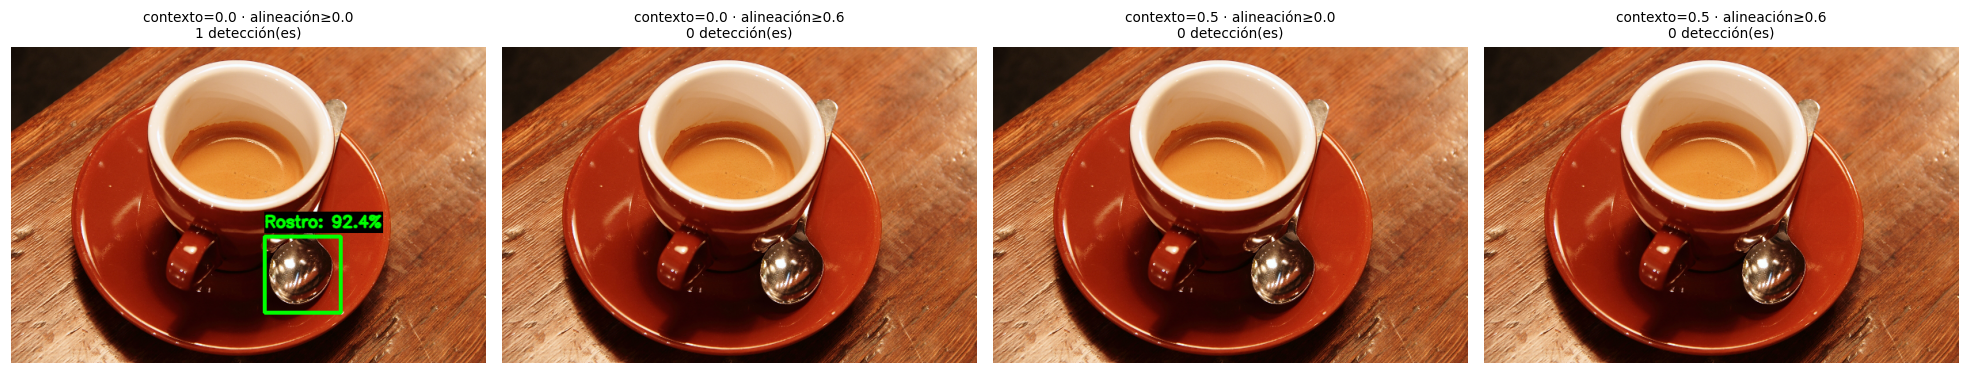

**Conclusión.** 1 de 4 combinaciones produjeron falsos positivos: contexto=0.0 y alineación=0.0 → 1 detección(es), confianza máx. 0.924. Activar cualquiera de los dos mecanismos bastó para eliminarlo en esta imagen.

In [12]:
cafe_bgr = rgb2bgr(casos[3][1])
filas_abl, res_abl = [], {}
for ctx in (0.0, CONTEXT):
    for mc in (0.0, MIN_COVER):
        print(f"▶ contexto={ctx} · alineación mínima={mc} ...", flush=True)
        r = detectar(cafe_bgr, 16, 1.25, context=ctx, min_cover=mc)
        res_abl[(ctx, mc)] = r
        filas_abl.append({"Contexto (× lado)": ctx, "Alineación mín.": mc,
                          "Ventanas aceptadas": r["detecciones_brutas"],
                          "Detecciones finales": r["detecciones_finales"],
                          "Confianza máx. FP": round(float(r["scores"].max()), 3) if len(r["scores"]) else 0.0,
                          "Tiempo (s)": round(r["tiempo_s"], 1)})
df_abl = pd.DataFrame(filas_abl); TABLAS["ablacion_caso3"] = df_abl
display(df_abl)

fig, axs = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, ((ctx, mc), r) in zip(axs, res_abl.items()):
    ax.imshow(bgr2rgb(draw_detections(cafe_bgr, r["boxes"], r["scores"]))); ax.axis("off")
    ax.set_title(f"contexto={ctx} · alineación≥{mc}\n{r['detecciones_finales']} detección(es)", fontsize=9)
plt.tight_layout(); guardar_fig("ablacion_contexto.png"); plt.show()

# Conclusión generada desde la tabla
con_fp = df_abl[df_abl["Detecciones finales"] > 0].to_dict("records")
if not con_fp:
    texto_abl = "Ninguna de las 4 combinaciones produjo falsos positivos en esta imagen."
else:
    lista = "; ".join(f"contexto={f['Contexto (× lado)']} y alineación={f['Alineación mín.']} → "
                      f"{f['Detecciones finales']} detección(es), confianza máx. {f['Confianza máx. FP']}" for f in con_fp)
    texto_abl = f"{len(con_fp)} de 4 combinaciones produjeron falsos positivos: {lista}."
    if len(con_fp) == 1 and con_fp[0]["Contexto (× lado)"] == 0 and con_fp[0]["Alineación mín."] == 0:
        texto_abl += " Activar cualquiera de los dos mecanismos bastó para eliminarlo en esta imagen."
display(Markdown("**Conclusión.** " + texto_abl))

## 8 · Ablación del tamaño de ventana
Se compara la ventana de **64, 96 y 128 px** con **paso = 25 % de la ventana** (16, 24 y 32 px), **escala 1.40**, confianza 0.90, NMS 0.30 y los mismos mecanismos de alineación, contexto y contención. Se evalúan el **Caso 1** (rostro ≈ 100 px) y el **Caso 2** (rostro ≈ 190 px). Como el paso crece con la ventana, la tabla refleja el efecto conjunto de tamaño y densidad de barrido, no el de la ventana aislada. Cada combinación es una sola ejecución (la del Caso 1 con 96 px es el *Paso Rápido* y se reutiliza); los tiempos dependen de la máquina.

**Falsos positivos.** Una detección cuyo centro cae fuera de un recuadro de referencia del rostro, trazado a mano (aproximado) sobre cada imagen, se cuenta como falso positivo y se dibuja en **rojo**.

In [13]:
ABL_VENTANAS = (64, 96, 128)
ABL_SCALE    = 1.40
ABL_CASOS    = (1, 2)
paso_de = lambda w: w // 4           # 25 % de la ventana -> 16, 24, 32 px

# Rostro de cada caso (x1, y1, x2, y2) en px de la imagen original: anotación manual aproximada, con la cabeza completa
ROSTRO_REF = {1: (150, 50, 290, 195), 2: (110, 70, 370, 370)}
def es_falso_positivo(caja, ref):
    cx, cy = (caja[0] + caja[2]) / 2, (caja[1] + caja[3]) / 2
    return not (ref[0] <= cx <= ref[2] and ref[1] <= cy <= ref[3])

res_vent, filas_vent = {}, []
for k in ABL_CASOS:
    img_k = rgb2bgr(casos[k][1])
    for w in ABL_VENTANAS:
        step = paso_de(w)
        print(f"▶ Caso {k} · ventana {w} px · paso {step} ...", flush=True)
        r = detectar(img_k, step, ABL_SCALE, ventana=w)
        res_vent[(k, w)] = r
        fp = [bool(es_falso_positivo(b, ROSTRO_REF[k])) for b in r["boxes"]]
        cajas = "; ".join(f"{int(b[2] - b[0])}×{int(b[3] - b[1])}" + (" (FP)" if f else "") for b, f in zip(r["boxes"], fp)) or "—"
        filas_vent.append({
            "Caso": k, "Ventana (px)": w, "Paso (px)": step,
            "Niveles de pirámide": r["niveles"], "Ventanas evaluadas": r["total_ventanas"],
            "Detecciones brutas": r["detecciones_brutas"], "Detecciones finales": r["detecciones_finales"],
            "Falsos positivos": int(sum(fp)), "Caja final (px)": cajas, "Tiempo (s)": round(r["tiempo_s"], 2),
        })
        print(f"   {r['total_ventanas']} ventanas · {r['detecciones_brutas']} brutas → {r['detecciones_finales']} finales ({sum(fp)} FP) · {r['tiempo_s']:.1f} s")

df_vent = pd.DataFrame(filas_vent)
df_vent["Ventanas/s"] = (df_vent["Ventanas evaluadas"] / df_vent["Tiempo (s)"]).round(1)
TABLAS["ablacion_tamano_ventana"] = df_vent
display(df_vent)

▶ Caso 1 · ventana 64 px · paso 16 ...
   1465 ventanas · 16 brutas → 2 finales (1 FP) · 44.1 s
▶ Caso 1 · ventana 96 px · paso 24 ...
   (corrida idéntica ya ejecutada: se reutiliza el resultado)
   537 ventanas · 4 brutas → 1 finales (0 FP) · 16.2 s
▶ Caso 1 · ventana 128 px · paso 32 ...
   263 ventanas · 1 brutas → 1 finales (0 FP) · 7.8 s
▶ Caso 2 · ventana 64 px · paso 16 ...
   1425 ventanas · 11 brutas → 1 finales (0 FP) · 42.2 s
▶ Caso 2 · ventana 96 px · paso 24 ...
   535 ventanas · 14 brutas → 1 finales (0 FP) · 15.9 s
▶ Caso 2 · ventana 128 px · paso 32 ...
   238 ventanas · 14 brutas → 1 finales (0 FP) · 7.1 s


,Caso,Ventana (px),Paso (px),Niveles de pirámide,Ventanas evaluadas,Detecciones brutas,Detecciones finales,Falsos positivos,Caja final (px),Tiempo (s),Ventanas/s
0,1,64,16,7,1465,16,2,1,64×64; 125×126 (FP),44.07,33.2
1,1,96,24,5,537,4,1,0,96×96,16.20,33.1
2,1,128,32,5,263,1,1,0,128×128,7.84,33.5
3,2,64,16,7,1425,11,1,0,175×175,42.20,33.8
4,2,96,24,5,535,14,1,0,188×188,15.87,33.7
5,2,128,32,4,238,14,1,0,180×179,7.06,33.7


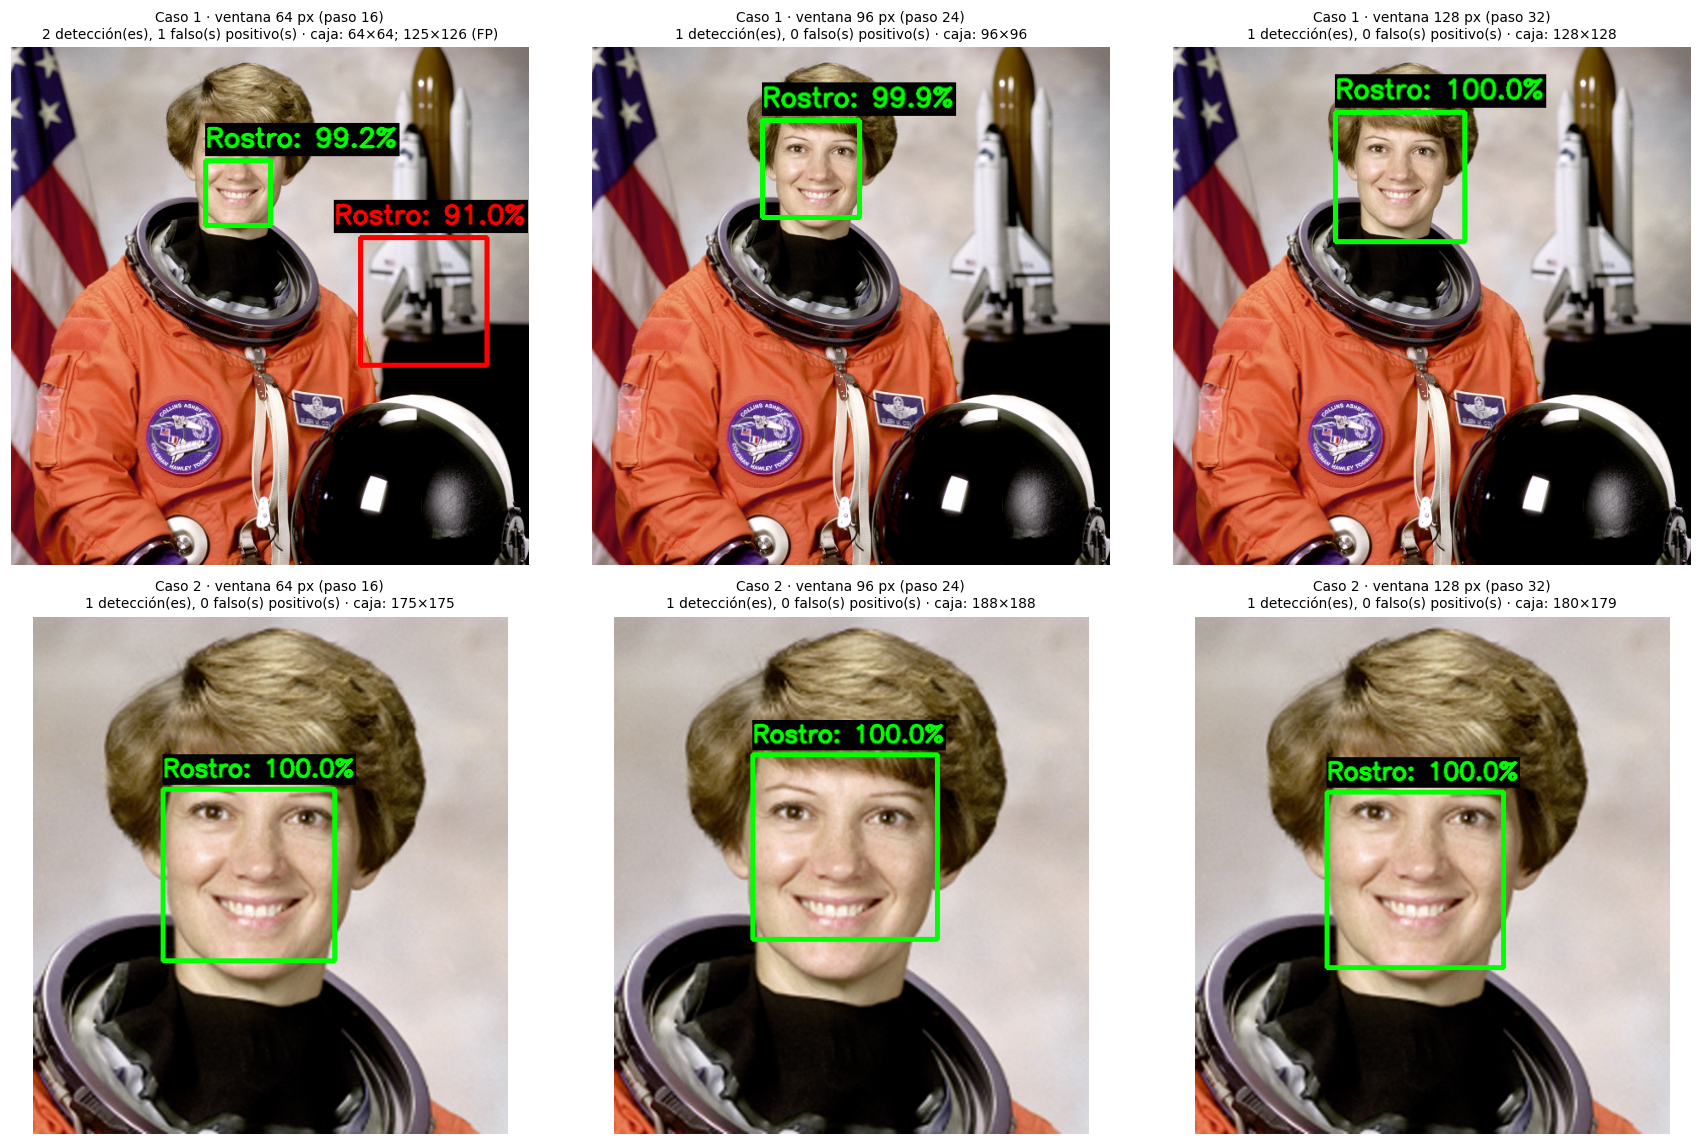

In [14]:
# Galería: filas = casos, columnas = tamaño de ventana; aciertos en verde, falsos positivos en rojo (3 px)
fig, axs = plt.subplots(len(ABL_CASOS), len(ABL_VENTANAS), figsize=(16, 10.5))
for i, k in enumerate(ABL_CASOS):
    img_k = rgb2bgr(casos[k][1])
    for j, w in enumerate(ABL_VENTANAS):
        r = res_vent[(k, w)]; ax = axs[i, j]
        es_fp = np.array([es_falso_positivo(b, ROSTRO_REF[k]) for b in r["boxes"]], dtype=bool)
        vis = draw_detections(img_k, r["boxes"][~es_fp], r["scores"][~es_fp], color=(0, 255, 0))
        vis = draw_detections(vis, r["boxes"][es_fp], r["scores"][es_fp], color=(0, 0, 255))
        fila = df_vent[(df_vent["Caso"] == k) & (df_vent["Ventana (px)"] == w)].iloc[0]
        ax.imshow(bgr2rgb(vis))
        ax.set_title(f"Caso {k} · ventana {w} px (paso {paso_de(w)})\n"
                     f"{r['detecciones_finales']} detección(es), {fila['Falsos positivos']} falso(s) positivo(s) · caja: {fila['Caja final (px)']}", fontsize=9)
        ax.axis("off")
plt.tight_layout(); guardar_fig("ablacion_ventana.png"); plt.show()

In [15]:
# Conclusión generada desde df_vent (no escrita a mano, para que siempre coincida con la tabla)
def _frag_caso(k):
    sub = df_vent[df_vent["Caso"] == k]
    return f"Caso {k}: " + ", ".join(
        f"{int(f['Ventana (px)'])} px → {int(f['Detecciones finales'])} final(es), {int(f['Falsos positivos'])} FP [{f['Caja final (px)']}]"
        for _, f in sub.iterrows())

def _costo_caso(k):
    sub = df_vent[df_vent["Caso"] == k].sort_values("Ventana (px)")
    a, b = sub.iloc[0], sub.iloc[-1]
    return (f"Caso {k}: {int(a['Ventanas evaluadas'])} ventanas / {a['Tiempo (s)']:.1f} s con {int(a['Ventana (px)'])} px "
            f"frente a {int(b['Ventanas evaluadas'])} / {b['Tiempo (s)']:.1f} s con {int(b['Ventana (px)'])} px")

fps = [(k, w, f"{int(b[2] - b[0])}×{int(b[3] - b[1])}", float(sc))
       for (k, w), r in res_vent.items() for b, sc in zip(r["boxes"], r["scores"]) if es_falso_positivo(b, ROSTRO_REF[k])]
n_fp = len(fps)
texto_fp = "; ".join(f"Caso {k}, ventana {w} px: caja {tam} con {sc * 100:.1f} %" for k, w, tam, sc in fps)
texto_ventana = ("Con paso = 25 % de la ventana, escala 1.40, confianza 0.90 y NMS 0.30, las detecciones finales "
                 f"(tamaño de la caja en la imagen original) fueron: {'; '.join(_frag_caso(k) for k in ABL_CASOS)}. "
                 f"El costo fue {'; '.join(_costo_caso(k) for k in ABL_CASOS)}. "
                 f"Falsos positivos totales: {n_fp}" + (f" ({texto_fp})." if n_fp else "."))
if (1, 64) in {(k, w) for k, w, _, _ in fps}:
    # Observación de la revisión visual de la galería (ablacion_ventana.png)
    texto_ventana += (" Revisión visual de la galería: la segunda caja del Caso 1 con ventana de 64 px no está sobre un rostro sino sobre el "
                      "transbordador del fondo, es decir, es un **falso positivo** que supera el umbral 0.90. "
                      "La otra caja de 64 px sí está sobre el rostro, pero lo recorta (cubre solo su zona inferior), mientras que las de 96 y 128 px lo encuadran completo. "
                      "Por tanto, la ventana de 64 px no mejora el resultado: añade un falso positivo y evalúa más ventanas.")
display(Markdown("**Conclusión.** " + texto_ventana))

**Conclusión.** Con paso = 25 % de la ventana, escala 1.40, confianza 0.90 y NMS 0.30, las detecciones finales (tamaño de la caja en la imagen original) fueron: Caso 1: 64 px → 2 final(es), 1 FP [64×64; 125×126 (FP)], 96 px → 1 final(es), 0 FP [96×96], 128 px → 1 final(es), 0 FP [128×128]; Caso 2: 64 px → 1 final(es), 0 FP [175×175], 96 px → 1 final(es), 0 FP [188×188], 128 px → 1 final(es), 0 FP [180×179]. El costo fue Caso 1: 1465 ventanas / 44.1 s con 64 px frente a 263 / 7.8 s con 128 px; Caso 2: 1425 ventanas / 42.2 s con 64 px frente a 238 / 7.1 s con 128 px. Falsos positivos totales: 1 (Caso 1, ventana 64 px: caja 125×126 con 91.0 %). Revisión visual de la galería: la segunda caja del Caso 1 con ventana de 64 px no está sobre un rostro sino sobre el transbordador del fondo, es decir, es un **falso positivo** que supera el umbral 0.90. La otra caja de 64 px sí está sobre el rostro, pero lo recorta (cubre solo su zona inferior), mientras que las de 96 y 128 px lo encuadran completo. Por tanto, la ventana de 64 px no mejora el resultado: añade un falso positivo y evalúa más ventanas.

## 9 · Desafío 2b: rostro menor que la ventana (FASE 2)
La pirámide clásica solo reduce, así que un rostro menor que ≈ 0.775 × 96 ≈ 74 px no alinea con la ventana (alineación < 0.60). `upsample_levels = n` agrega $n$ niveles de ampliación con $s=\text{escala}^{-k}$ ($k=1..n$, `INTER_CUBIC`), y el rostro mínimo detectable baja a $0.775\cdot 96\cdot\text{escala}^{-n}$ px.

**Prueba.** `data.astronaut()` reducida con factor 0.6 (307×307; rostro ≈ 0.6 × 96 ≈ 58 px, tomando como referencia la caja final del Caso 1), con `upsample_levels` = 0, 1 y 2, paso 24 y escala 1.40. El costo crece porque la imagen ampliada genera más ventanas.

In [16]:
astro_s = cv2.resize(data.astronaut(), None, fx=0.6, fy=0.6, interpolation=cv2.INTER_AREA)   # RGB, 307×307
astro_s_bgr = rgb2bgr(astro_s)
ROSTRO_REF_2B = tuple(0.6 * v for v in ROSTRO_REF[1])            # mismo recuadro de referencia, reducido 0.6
cara_px = 0.6 * float(res_casos[1]["boxes"][0][2] - res_casos[1]["boxes"][0][0])
print(f"Imagen {astro_s.shape[1]}×{astro_s.shape[0]} · rostro ≈ {cara_px:.0f} px")

UP_NIVELES, UP_STEP, UP_SCALE = (0, 1, 2), 24, 1.40
res_2b, filas_2b = {}, []
for up in UP_NIVELES:
    print(f"▶ upsample_levels={up} ...", flush=True)
    r = detectar(astro_s_bgr, UP_STEP, UP_SCALE, upsample=up)
    res_2b[up] = r
    fp = [bool(es_falso_positivo(b, ROSTRO_REF_2B)) for b in r["boxes"]]
    cajas = "; ".join(f"{int(b[2]-b[0])}×{int(b[3]-b[1])}" + (" (FP)" if f else "") for b, f in zip(r["boxes"], fp)) or "—"
    filas_2b.append({"Niveles de ampliación": up, "Niveles de pirámide": r["niveles"],
                     "Ventanas evaluadas": r["total_ventanas"], "Detecciones brutas": r["detecciones_brutas"],
                     "Detecciones finales": r["detecciones_finales"], "Falsos positivos": int(sum(fp)),
                     "Caja final en el original (px)": cajas,
                     "Rostro mín. detectable (px)": round(r["tam_min_rostro_px"], 1),
                     "Tiempo (s)": round(r["tiempo_s"], 2)})
    print(f"   {r['total_ventanas']} ventanas · {r['detecciones_brutas']} brutas → {r['detecciones_finales']} finales · {r['tiempo_s']:.1f} s")
df_2b = pd.DataFrame(filas_2b); TABLAS["desafio_2b"] = df_2b
display(df_2b)

# Pirámide del caso más ampliado, en la misma forma que la tabla de la sección 4 (consistente con las ventanas evaluadas)
TABLAS["piramide_desafio_2b"] = tabla_piramide(astro_s, UP_STEP, UP_SCALE, max(UP_NIVELES))
assert TABLAS["piramide_desafio_2b"]["Ventanas"].sum() == res_2b[max(UP_NIVELES)]["total_ventanas"]
display(Markdown(f"**Pirámide con {max(UP_NIVELES)} niveles de ampliación (paso {UP_STEP}, escala {UP_SCALE})**"))
display(TABLAS["piramide_desafio_2b"])

Imagen 307×307 · rostro ≈ 58 px
▶ upsample_levels=0 ...
   127 ventanas · 0 brutas → 0 finales · 3.8 s
▶ upsample_levels=1 ...
   323 ventanas · 2 brutas → 1 finales · 9.6 s
▶ upsample_levels=2 ...
   807 ventanas · 8 brutas → 1 finales · 23.0 s


,Niveles de ampliación,Niveles de pirámide,Ventanas evaluadas,Detecciones brutas,Detecciones finales,Falsos positivos,Caja final en el original (px),Rostro mín. detectable (px),Tiempo (s)
0,0,4,127,0,0,0,—,74.4,3.76
1,1,5,323,2,1,0,68×69,53.1,9.62
2,2,6,807,8,1,0,49×49,38.0,22.95


**Pirámide con 2 niveles de ampliación (paso 24, escala 1.4)**

,Nivel,Factor s,Imagen (px),Ventana efectiva en el original (px),Ventanas
0,-2,0.510,602×602,49.0,484
1,-1,0.714,430×430,68.6,196
2,0,1.000,307×307,96.0,81
3,1,1.400,219×219,134.4,36
4,2,1.960,157×157,188.2,9
5,3,2.744,112×112,263.4,1


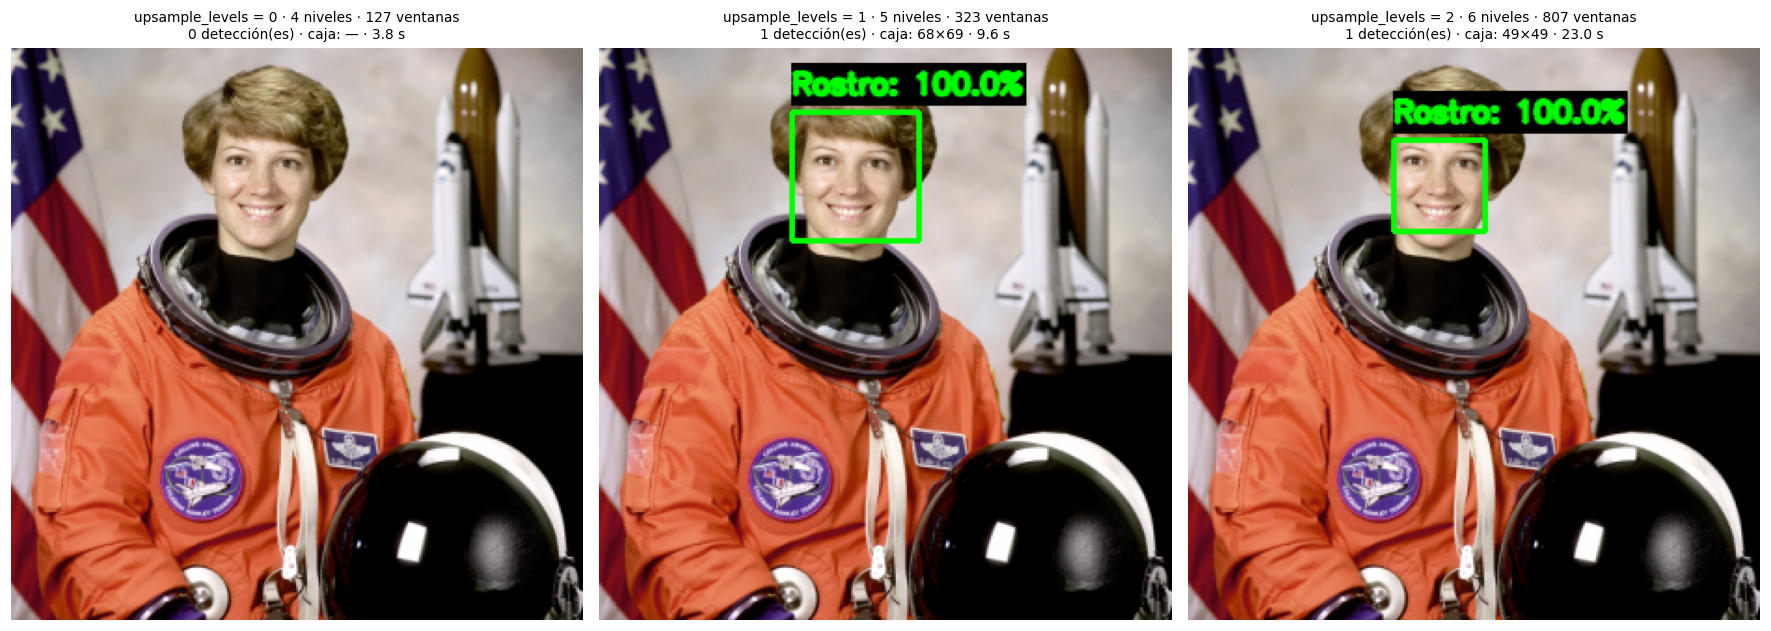

**Conclusión.** Con el rostro reducido a ≈ 58 px y un mínimo detectable de 74 px sin ampliación, `upsample_levels=0` produjo 0 detección(es) (0 FP). La primera configuración que detectó el rostro fue `upsample_levels=1` (mínimo detectable 53 px; caja de 68×69 en el original), con 323 ventanas / 9.6 s frente a 127 / 3.8 s sin ampliar (2.5× las ventanas). Con `upsample_levels=2` hubo 1 detección(es) final(es) (0 FP), 807 ventanas y 22.9 s.

In [17]:
fig, axs = plt.subplots(1, len(UP_NIVELES), figsize=(5.4 * len(UP_NIVELES), 5.6))
for ax, up in zip(axs, UP_NIVELES):
    r = res_2b[up]
    es_fp = np.array([es_falso_positivo(b, ROSTRO_REF_2B) for b in r["boxes"]], dtype=bool)
    vis = draw_detections(astro_s_bgr, r["boxes"][~es_fp], r["scores"][~es_fp], color=(0, 255, 0), thickness=2)
    vis = draw_detections(vis, r["boxes"][es_fp], r["scores"][es_fp], color=(0, 0, 255), thickness=2)
    fila = df_2b[df_2b["Niveles de ampliación"] == up].iloc[0]
    ax.imshow(bgr2rgb(vis)); ax.axis("off")
    ax.set_title(f"upsample_levels = {up} · {r['niveles']} niveles · {r['total_ventanas']} ventanas\n"
                 f"{r['detecciones_finales']} detección(es) · caja: {fila['Caja final en el original (px)']} · {r['tiempo_s']:.1f} s", fontsize=9)
plt.tight_layout(); guardar_fig("desafio_2b_galeria.png"); plt.show()

# Conclusión generada desde df_2b
bien = df_2b[(df_2b["Detecciones finales"] - df_2b["Falsos positivos"]) > 0]
f0 = df_2b.iloc[0]
texto_2b = (f"Con el rostro reducido a ≈ {cara_px:.0f} px y un mínimo detectable de {f0['Rostro mín. detectable (px)']:.0f} px sin ampliación, "
            f"`upsample_levels=0` produjo {int(f0['Detecciones finales'])} detección(es) ({int(f0['Falsos positivos'])} FP). ")
if bien.empty:
    texto_2b += "Ninguna de las configuraciones probadas detectó el rostro."
else:
    p = bien.iloc[0]
    texto_2b += (f"La primera configuración que detectó el rostro fue `upsample_levels={int(p['Niveles de ampliación'])}` "
                 f"(mínimo detectable {p['Rostro mín. detectable (px)']:.0f} px; caja de {p['Caja final en el original (px)']} en el original), "
                 f"con {int(p['Ventanas evaluadas'])} ventanas / {p['Tiempo (s)']:.1f} s frente a {int(f0['Ventanas evaluadas'])} / {f0['Tiempo (s)']:.1f} s sin ampliar "
                 f"({p['Ventanas evaluadas'] / f0['Ventanas evaluadas']:.1f}× las ventanas).")
ult = df_2b.iloc[-1]
if len(df_2b) > 2 and int(ult["Niveles de ampliación"]) > int(bien.iloc[0]["Niveles de ampliación"] if not bien.empty else -1):
    texto_2b += (f" Con `upsample_levels={int(ult['Niveles de ampliación'])}` hubo {int(ult['Detecciones finales'])} detección(es) final(es) "
                 f"({int(ult['Falsos positivos'])} FP), {int(ult['Ventanas evaluadas'])} ventanas y {ult['Tiempo (s)']:.1f} s.")
display(Markdown("**Conclusión.** " + texto_2b))

## 10 · Análisis y conclusiones

In [18]:
b = df_bench.set_index("Configuración")
fino, est, rap = b.loc["Paso Fino"], b.loc["Paso Estándar"], b.loc["Paso Rápido"]
finales_b = set(int(v) for v in df_bench["Detecciones finales (NMS)"])
lado2 = int(res_casos[2]["boxes"][0][2] - res_casos[2]["boxes"][0][0])
niv2 = np.log(lado2 / 96) / np.log(1.25)

puntos = [
    f"**Costo.** Las ventanas crecen con ≈ 1/paso² y con el número de niveles: Paso Fino {int(fino['Ventanas evaluadas'])} ventanas "
    f"({int(fino['Niveles de pirámide'])} niveles), Estándar {int(est['Ventanas evaluadas'])} ({int(est['Niveles de pirámide'])}) y "
    f"Rápido {int(rap['Ventanas evaluadas'])} ({int(rap['Niveles de pirámide'])}). El rendimiento fue casi constante "
    f"(≈ {df_bench['Ventanas/s'].mean():.0f} ventanas/s), así que el tiempo es proporcional a las ventanas: "
    f"{fino['Tiempo (s)']:.0f} s, {est['Tiempo (s)']:.0f} s y {rap['Tiempo (s)']:.0f} s; el paso fino costó {fino['Tiempo (s)'] / rap['Tiempo (s)']:.1f}× el rápido.",

    (f"**Calidad (Caso 1).** Las tres configuraciones terminan con {finales_b.pop()} recuadro(s) final(es) "
     f"(confianza máx. {fino['Confianza máx.']}, {est['Confianza máx.']} y {rap['Confianza máx.']}); el paso fino acepta más ventanas brutas "
     f"({int(fino['Detecciones brutas'])} vs {int(est['Detecciones brutas'])} vs {int(rap['Detecciones brutas'])}), que el NMS colapsa, sin cambiar el número de rostros. "
     "Un paso más fino no mejoró el resultado en esta imagen, pero sí multiplicó el costo.")
    if len(finales_b) == 1 else
    "**Calidad (Caso 1).** Las configuraciones no coinciden en el número de recuadros finales; ver la tabla de la sección 5.",

    f"**Desafío 2a (rostro mayor que la ventana).** En el Caso 2 la caja final mide {lado2} px en la imagen original "
    f"(≈ 96·1.25^{niv2:.1f}): se detectó en el nivel {nivel} de la pirámide, donde el rostro cabe en la ventana fija.",

    "**Desafío 2b (rostro menor que la ventana).** " + texto_2b,

    f"**Falsos positivos.** {texto_abl} En la ablación de tamaño de ventana hubo {n_fp} falso(s) positivo(s)"
    + (f" ({texto_fp}): superan el umbral 0.90, que por sí solo no basta." if n_fp else "."),
]
texto_conclusiones = puntos
display(Markdown("\n\n".join(puntos)))
display(Markdown(
    "**Limitaciones.** (1) El recuadro es la ventana cuadrada, no la caja ajustada del rostro (en el Caso 2 recorta parte de la frente). "
    "(2) Con entrada fija de 300×300 y CPU, escanear con el SSD es lento; aplicado a la imagen completa tarda milisegundos y es la forma eficiente en producción, "
    "mientras que la ventana deslizante es el ejercicio didáctico. "
    "(3) Los umbrales (0.90, alineación 0.60, contención 0.40) se ajustaron mirando estas imágenes; no hay conjunto de validación ni métricas de precisión/recall, "
    "y cada configuración es una sola ejecución. "
    "(4) Los recuadros de referencia del rostro (sección 8) son anotaciones manuales aproximadas. "
    "(5) No se probaron rostros ocluidos ni de perfil."))

**Costo.** Las ventanas crecen con ≈ 1/paso² y con el número de niveles: Paso Fino 8676 ventanas (13 niveles), Estándar 1574 (8) y Rápido 537 (5). El rendimiento fue casi constante (≈ 34 ventanas/s), así que el tiempo es proporcional a las ventanas: 258 s, 47 s y 16 s; el paso fino costó 15.9× el rápido.

**Calidad (Caso 1).** Las tres configuraciones terminan con 1 recuadro(s) final(es) (confianza máx. 1.0, 1.0 y 0.9993); el paso fino acepta más ventanas brutas (78 vs 15 vs 4), que el NMS colapsa, sin cambiar el número de rostros. Un paso más fino no mejoró el resultado en esta imagen, pero sí multiplicó el costo.

**Desafío 2a (rostro mayor que la ventana).** En el Caso 2 la caja final mide 188 px en la imagen original (≈ 96·1.25^3.0): se detectó en el nivel 3 de la pirámide, donde el rostro cabe en la ventana fija.

**Desafío 2b (rostro menor que la ventana).** Con el rostro reducido a ≈ 58 px y un mínimo detectable de 74 px sin ampliación, `upsample_levels=0` produjo 0 detección(es) (0 FP). La primera configuración que detectó el rostro fue `upsample_levels=1` (mínimo detectable 53 px; caja de 68×69 en el original), con 323 ventanas / 9.6 s frente a 127 / 3.8 s sin ampliar (2.5× las ventanas). Con `upsample_levels=2` hubo 1 detección(es) final(es) (0 FP), 807 ventanas y 22.9 s.

**Falsos positivos.** 1 de 4 combinaciones produjeron falsos positivos: contexto=0.0 y alineación=0.0 → 1 detección(es), confianza máx. 0.924. Activar cualquiera de los dos mecanismos bastó para eliminarlo en esta imagen. En la ablación de tamaño de ventana hubo 1 falso(s) positivo(s) (Caso 1, ventana 64 px: caja 125×126 con 91.0 %): superan el umbral 0.90, que por sí solo no basta.

**Limitaciones.** (1) El recuadro es la ventana cuadrada, no la caja ajustada del rostro (en el Caso 2 recorta parte de la frente). (2) Con entrada fija de 300×300 y CPU, escanear con el SSD es lento; aplicado a la imagen completa tarda milisegundos y es la forma eficiente en producción, mientras que la ventana deslizante es el ejercicio didáctico. (3) Los umbrales (0.90, alineación 0.60, contención 0.40) se ajustaron mirando estas imágenes; no hay conjunto de validación ni métricas de precisión/recall, y cada configuración es una sola ejecución. (4) Los recuadros de referencia del rostro (sección 8) son anotaciones manuales aproximadas. (5) No se probaron rostros ocluidos ni de perfil.

## 11 · Exportación de entregables

In [19]:
def _j(o):
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, np.generic): return o.item()
    raise TypeError(type(o))

def resumen(r):
    return {"niveles": r["niveles"], "total_ventanas": r["total_ventanas"], "ventanas_por_nivel": r["ventanas_por_nivel"],
            "detecciones_brutas": r["detecciones_brutas"], "detecciones_finales": r["detecciones_finales"],
            "tiempo_s": round(r["tiempo_s"], 3), "cajas_finales_xyxy": r["boxes"].astype(int).tolist(),
            "confianzas_finales": [round(float(s), 5) for s in r["scores"]],
            "upsample_levels": r["upsample_levels"], "tam_min_rostro_px": round(r["tam_min_rostro_px"], 2)}

def res_ventana(k, w):
    r = res_vent[(k, w)]
    fila = df_vent[(df_vent["Caso"] == k) & (df_vent["Ventana (px)"] == w)].iloc[0]
    return {"caso": casos[k][0], "ventana_px": int(w), "paso_px": int(paso_de(w)), **resumen(r),
            "ventanas_evaluadas": int(r["total_ventanas"]), "falsos_positivos": int(fila["Falsos positivos"]),
            "tamano_cajas_finales_px": [[int(b[2] - b[0]), int(b[3] - b[1])] for b in r["boxes"]],
            "ventanas_por_s": float(fila["Ventanas/s"])}

resultados = {
    "practica": "Práctica 6 · Detección de rostros (ventana deslizante + pirámide de imágenes)",
    "entorno": {"opencv": cv2.__version__, "numpy": np.__version__, "pandas": pd.__version__},
    "modelo": {"arquitectura": "ResNet-10 SSD (Caffe)", "prototxt": p6.PROTO_NAME, "pesos": p6.MODEL_NAME,
               "entrada_red": list(p6.NET_INPUT)},
    "parametros_globales": {"window_size": list(WINDOW), "conf_threshold": CONF_THR, "nms_overlap": NMS_THR,
                            "batch_size": BATCH, "min_alineacion": MIN_COVER, "context_margin": CONTEXT,
                            "contain_thresh": CONTAIN, "upsample_levels": 0},
    "piramide_caso1": {"estandar_paso16_escala1.25": TABLAS["piramide_estandar"].to_dict("records"),
                       "rapida_paso24_escala1.40": TABLAS["piramide_rapida"].to_dict("records")},
    "benchmark_caso1": [{**fila, "ventanas_por_nivel": res_bench[fila["Configuración"]]["ventanas_por_nivel"]}
                        for fila in df_bench.to_dict("records")],
    "casos_configuracion_estandar": {casos[k][0]: {**resumen(res_casos[k]), "imagen_px": list(casos[k][1].shape[1::-1])}
                                     for k in (1, 2, 3)},
    "mapeo_inverso_ejemplo": MAPEO_EJEMPLO,
    "regresion_sin_ampliacion": df_reg.to_dict("records"),
    "ablacion_caso3": df_abl.to_dict("records"),
    "ablacion_caso3_conclusion": texto_abl,
    "ablacion_tamano_ventana": {
        "parametros": {"ventanas_px": list(ABL_VENTANAS), "paso": "25 % de la ventana", "scale": ABL_SCALE,
                       "conf_threshold": CONF_THR, "nms_overlap": NMS_THR, "min_alineacion": MIN_COVER,
                       "context_margin": CONTEXT, "contain_thresh": CONTAIN, "batch_size": BATCH,
                       "rostro_referencia_xyxy": {str(k): list(v) for k, v in ROSTRO_REF.items()}},
        "resultados": [res_ventana(k, w) for k in ABL_CASOS for w in ABL_VENTANAS],
        "conclusion": texto_ventana},
    "desafio_2b": {
        "parametros": {"imagen": "data.astronaut() reducida x0.6", "imagen_px": list(astro_s.shape[1::-1]),
                       "rostro_aprox_px": round(cara_px, 1), "paso": UP_STEP, "scale": UP_SCALE,
                       "upsample_levels": list(UP_NIVELES), "rostro_referencia_xyxy": [round(v, 1) for v in ROSTRO_REF_2B]},
        "tabla": df_2b.to_dict("records"),
        "resultados": {str(up): resumen(res_2b[up]) for up in UP_NIVELES},
        "piramide_mayor_ampliacion": TABLAS["piramide_desafio_2b"].to_dict("records"),
        "conclusion": texto_2b},
    "conclusiones": texto_conclusiones,
}
ruta_json = os.path.join(OUT_DIR, "resultados_practica6.json")
with open(ruta_json, "w", encoding="utf-8") as f:
    json.dump(resultados, f, ensure_ascii=False, indent=2, default=_j)
print("✔ JSON guardado:", ruta_json)

# Prueba rápida de la línea de comandos con --upsample (configuración propia, no repite ninguna corrida anterior)
cv2.imwrite("desafio2b_astronaut_x0.6.png", astro_s_bgr)
cmd = [sys.executable, "practica_6_deteccion_rostros.py", "desafio2b_astronaut_x0.6.png", "--step", "48", "--scale", "1.4",
       "--upsample", "1", "--modelo-dir", os.path.join(OUT_DIR, "models"), "--salida", "prueba_cli.png"]
p = subprocess.run(cmd, capture_output=True, text=True)
print("$ " + " ".join(os.path.basename(c) if i == 0 else c for i, c in enumerate(cmd[1:])) + "\n" + p.stdout + p.stderr[-300:])
assert p.returncode == 0 and "Niveles: 5" in p.stdout, "La prueba de la línea de comandos con --upsample falló"

✔ JSON guardado: /kaggle/working/resultados_practica6.json
$ practica_6_deteccion_rostros.py desafio2b_astronaut_x0.6.png --step 48 --scale 1.4 --upsample 1 --modelo-dir /kaggle/working/models --salida prueba_cli.png
Niveles: 5 | Ventanas: 88 | Brutas: 1 | Finales: 1 | Tiempo: 2.8 s
Rostro mínimo detectable ≈ 53 px (con 1 nivel(es) de ampliación)
  Rostro 100.0%  caja=[103, 34, 171, 103]
Resultado guardado en prueba_cli.png



In [20]:
# Entregables: módulo (.py), JSON y figuras PNG
ruta_py = os.path.join(OUT_DIR, "practica_6_deteccion_rostros.py")
with open(ruta_py, "rb") as f:
    contenido = f.read()
print(f"practica_6_deteccion_rostros.py · {len(contenido)} bytes · SHA-256 {hashlib.sha256(contenido).hexdigest()}\n")

print("Archivos exportados en", OUT_DIR)
for f in ["practica_6_deteccion_rostros.py", "resultados_practica6.json"] + FIGURAS:
    ruta = os.path.join(OUT_DIR, f)
    print((" ✔ " if os.path.exists(ruta) else " ✘ ") + f, f"({os.path.getsize(ruta)/1024:.0f} KB)" if os.path.exists(ruta) else "")
assert all(os.path.exists(os.path.join(OUT_DIR, f)) for f in FIGURAS), "Falta alguna figura"

practica_6_deteccion_rostros.py · 27772 bytes · SHA-256 eb2cc74de931c75f74a1f679124ba0e24813f99a4e7bccf04039f0329d938995

Archivos exportados en /kaggle/working
 ✔ practica_6_deteccion_rostros.py (27 KB)
 ✔ resultados_practica6.json (22 KB)
 ✔ dataset_evaluacion_deteccion.png (1117 KB)
 ✔ piramide_imagenes.png (653 KB)
 ✔ comparativa_configuraciones.png (623 KB)
 ✔ benchmark_rendimiento.png (27 KB)
 ✔ galeria_deteccion_rostros.png (1350 KB)
 ✔ mapeo_inverso.png (720 KB)
 ✔ ablacion_contexto.png (334 KB)
 ✔ ablacion_ventana.png (964 KB)
 ✔ desafio_2b_galeria.png (857 KB)
